# **Machine Learning and Artificial Intelligence Project**
### Bocconi University, May 2024

- **Rebecca Metallo** (ID: 3171918)
- **Lisa Irle**       (ID:  3159247)
- **Mariam Alavidze** (ID: 3177419)
- **Elisavet Machaira**(ID: 3152697)

# Research question
-----------------
#### Evaluating Pre-Trained Computer Vision Models and Data Augmentation Techniques on Animal Image Classification: A Comparative Analysis of Performance Across 90 Animal Species

### **Importation of useful libraries** 

In [ ]:
import os
import time
import copy
import random
from shutil import copytree, shutil

import numpy as np
import pandas as pd
import cv2
from PIL import Image, ImageEnhance, ImageOps
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import KFold
from scipy.ndimage import gaussian_filter, map_coordinates

import torch
from torch import nn
import torch.optim as optim
from torch.optim import lr_scheduler
from torch.utils.data import Dataset, DataLoader, Subset
import torchvision
from torchvision import models, transforms, datasets
from torchvision.transforms import functional as F
from torchvision.transforms import ToTensor

from transformers import (
    ViTImageProcessor,
    ViTForImageClassification,
    SwinForImageClassification,
    AutoImageProcessor
)

from ultralytics import YOLO

# Print PyTorch and torchvision versions
print(f"PyTorch version: {torch.__version__}\ntorchvision version: {torchvision.__version__}")



## **Section 1: Data Augmentation**

In order to increase the amount of data we will train our models on, we have decided to implement multiple augmentation techniques, which will be further explained in each section. These will lead to having more differenciated data, and hopefully the model will manage to recognise animals also with lower quality thanks to the distortions applied on the training set. You will be able to see that also some randomizations have been applied. This is because we didn't want the dataset to bee too huge or too repetitive. So instead of having any kind of rotation, we will only have one random direction, and instead of having multiple brightness levels, we either make the image brighter or darker, etc.

####  **Section 1.1: Cropped images**

The first augmentation technique applied is a **random cropping**.
We had a few concerns about it, because we were afraid that the result of a cropping could lead us to having only grass, sky or water on the pic, so we had to be a bit creative about it. 

Our first idea was to detect the animals, do a first cropping in order to only have the animal on the picture, and then apply random croppings on the precropped image. 
**Why does this approach not work?**
 The image detection works, in some way, already as a classification. As the models we found are not trained on all the animals we have in our images, they won't be able to detect and crop, for example, an antilope. We were basically putting a step before the classification that needed classification in order to work.

 After realising this approach would not work, we decided to just keep the size of the images big enough in order to make sure we always have a part of the animal on the cropped image. Taking a quick look at our data, we have seen that the animals are usually pretty large and centered, so taking a size that is half the height and half the width should work well for our purposes. 

In [ ]:
def random_half_crop_and_save(image_path, output_folder):
    """Randomly crops an image to half size and saves it to a folder."""
    img = Image.open(image_path)
    width, height = img.size
    new_width, new_height = width // 2, height // 2

    max_x = width - new_width
    max_y = height - new_height
    x, y = random.randint(0, max_x), random.randint(0, max_y)

    cropped_img = img.crop((x, y, x + new_width, y + new_height))
    original_name, original_ext = os.path.splitext(os.path.basename(image_path))
    new_filename = f"{original_name}_cropped{original_ext}"
    output_path = os.path.join(output_folder, new_filename)
    os.makedirs(output_folder, exist_ok=True)

    cropped_img.save(output_path)



####  **Section 1.2: Stretches**

Another interesting augmentation technique is the one creating **stretched images**.
The possible directions are obviously vertical and horizontal, so we created a function that would randomly double either the height or the width of the initial image.

In [ ]:
def random_stretch_and_save(image_path, output_folder):
    """Randomly stretches an image and saves it with a unique name."""

    img = Image.open(image_path)
    width, height = img.size

    if random.choice([True, False]):
        new_width = width * 2
        new_height = height
        direction = "horizontal"
    else:
        new_width = width
        new_height = height * 2
        direction = "vertical"

    stretched_img = img.resize((new_width, new_height), Image.LANCZOS)

    original_name, original_ext = os.path.splitext(os.path.basename(image_path))
    new_filename = f"{original_name}_{direction}_stretched{original_ext}"
    output_path = os.path.join(output_folder, new_filename)
    os.makedirs(output_folder, exist_ok=True)

    stretched_img.save(output_path)


####  **Section 1.3: Rotations**

Here we apply a 90° **rotation** to the image. Again, we want to have some randomness, so the rotation can occur with a 50% chance each either clockwise or counterclockwise.

In [ ]:
def random_rotate_and_save(image_path, output_folder):
    """Randomly rotates an image by 90 degrees and saves it with a unique name."""

    img = Image.open(image_path)
    if random.choice([True, False]):
        rotation_angle = 90
        direction = "clockwise"
    else:
        rotation_angle = -90
        direction = "counterclockwise"

    rotated_img = img.rotate(rotation_angle, expand=True)  

    original_name, original_ext = os.path.splitext(os.path.basename(image_path))
    new_filename = f"{original_name}_{direction}_rotated{original_ext}"
    output_path = os.path.join(output_folder, new_filename)
    os.makedirs(output_folder, exist_ok=True)

    rotated_img.save(output_path)

####  **Section 1.4: Brightness**

The (almost) last technique we apply is a brightness adaptation. Here the image can either become **extremely bright or dark**. Again this happens with a 50% chance for each.

In [ ]:
def random_brightness_adjust_and_save(image_path, output_folder, max_brightness_change=0.9):
    """Randomly adjusts image brightness and saves it with a unique name."""

    img = Image.open(image_path)
    
    brightness_factor = 1 + random.uniform(-max_brightness_change, max_brightness_change)
    enhancer = ImageEnhance.Brightness(img)
    adjusted_img = enhancer.enhance(brightness_factor)
    if brightness_factor > 1:
        change_type = "brighter"
    else:
        change_type = "darker"
    original_name, original_ext = os.path.splitext(os.path.basename(image_path))
    new_filename = f"{original_name}_{change_type}{original_ext}"
    output_path = os.path.join(output_folder, new_filename)
    os.makedirs(output_folder, exist_ok=True)

    adjusted_img.save(output_path)


####  **Section 1.5: Random combination**

The actual last one is a random combination of the 4 techniques above. This will be implemented to each image only once, but there are **infinitely many possible outcomes** (without the cropping there would be 8 possible different outputs, but given that the possible random croppings are, not infinite because they are limited by the number of pixels, but still a really large number, the number of possible combinaitons is extremely high).

In [ ]:
def random_augment_and_save(image_path, output_folder, max_brightness_change=0.9):
    """Applies random brightness, rotation, stretching, and cropping to an image."""

    img = Image.open(image_path)

    # Brightness adjustment
    brightness_factor = 1 + random.uniform(-max_brightness_change, max_brightness_change)
    enhancer = ImageEnhance.Brightness(img)
    img = enhancer.enhance(brightness_factor)

    # Rotation
    rotation_angle = random.choice([90, -90])  
    img = img.rotate(rotation_angle, expand=True)

    # Stretching (either horizontal or vertical)
    if random.choice([True, False]):
        img = img.resize((img.width * 2, img.height), Image.LANCZOS)
    else:
        img = img.resize((img.width, img.height * 2), Image.LANCZOS)

    # Cropping (to half size)
    width, height = img.size
    new_width, new_height = width // 2, height // 2
    max_x = width - new_width
    max_y = height - new_height
    x, y = random.randint(0, max_x), random.randint(0, max_y)
    img = img.crop((x, y, x + new_width, y + new_height))

    original_name, original_ext = os.path.splitext(os.path.basename(image_path))
    new_filename = f"{original_name}_augmented{original_ext}" 
    output_path = os.path.join(output_folder, new_filename)
    os.makedirs(output_folder, exist_ok=True)

    img.save(output_path)

## **Section 2: Data Pre-Processing**

### **Section 2.1 = Splitting in train and test**

We will now split the data in train and test. This is done here for two main reasons: 
-   First of all we want the augmentation to be performed only on the train dataset, so it is convenient to do it now; 
-   Second of all, this gives us the possibility to always have the same training and testing data for each model and methodology we use.


 At first this might seem counterintuitive or counterproductive, but we believe that this could be interesting to have more precise comparisons. Especially since part of our main focus is comparing how well the models perform with augmented training data vs with the normal initial data, we believe that having the **same training and testing sets** can be extremely significant in our study.

In [ ]:

dataset_path = "C:\\Users\\Lisa\\Documents\\Uni\\ML and AI\\archive_copy\\animals"
train_path = "C:\\Users\\Lisa\\Documents\\Uni\\ML and AI\\archive_copy\\train"
val_path = "C:\\Users\\Lisa\\Documents\\Uni\\ML and AI\\archive_copy\\test"


os.makedirs(train_path, exist_ok=True)
os.makedirs(val_path, exist_ok=True)

class_directories = [d for d in os.listdir(dataset_path) if os.path.isdir(os.path.join(dataset_path, d))]

for class_dir in class_directories:
    class_path = os.path.join(dataset_path, class_dir)
    images = os.listdir(class_path)
    shuffle(images)  # Shuffle to randomize the files that go into train and val

   
    train_class_path = os.path.join(train_path, class_dir)
    val_class_path = os.path.join(val_path, class_dir)
    os.makedirs(train_class_path, exist_ok=True)
    os.makedirs(val_class_path, exist_ok=True)

    for i, image in enumerate(images):
        if i < 40:
            shutil.move(os.path.join(class_path, image), os.path.join(train_class_path, image))
        else:
            shutil.move(os.path.join(class_path, image), os.path.join(val_class_path, image))


### **Section 2.2 = Augmentation (only training data)**

What happens here precisely is the following:
-    We start by creating the augmented_train folder, which is a copy of the train folder. We do this in order to have all the images of the training data in the augmented folder also in their natural form. 
-   Then each of the above explained techniques is applied once to each image. This means that from each image, we will get, in the augmented folder, 6 images: the initial one, a cropped one, a rotaded one, a stretched one, one that is either bright or dark, and one that has a combination of all of these. That means that our training data for each animal, that first contained 40 images, now contains 240 ones.

In [ ]:
source_folder = "C:\\Users\\Lisa\\Documents\\Uni\\ML and AI\\archive_copy\\train"
output_folder = "C:\\Users\\Lisa\\Documents\\Uni\\ML and AI\\archive_copy\\augmented_train"
copytree(source_folder, output_folder)

for folder_name in os.listdir(output_folder):
    folder_path = os.path.join(output_folder, folder_name)
    for image_name in os.listdir(folder_path):
        if image_name.endswith((".jpg", ".jpeg", ".png")):  
            image_path = os.path.join(folder_path, image_name)
            random_half_crop_and_save(image_path, folder_path)
            random_stretch_and_save(image_path, folder_path)
            random_rotate_and_save(image_path, folder_path)
            random_brightness_adjust_and_save(image_path, folder_path)
            random_augment_and_save(image_path, folder_path)

In order to manage to use this data for training and testing, we need to match each image of an animal with the **correct label**. For this we create a **list of touples**, that contains, for each image:
-    the directory of the image 
-   its label. 

We do this for **normal train data, augmented train data and test data**.

In [ ]:
base_path= "C:\\Users\\Lisa\\Documents\\Uni\\ML and AI\\archive_copy\\animals"
species_folders = os.listdir(base_path)
print("Folders of species:", species_folders)

Folders of species: ['antelope', 'badger', 'bat', 'bear', 'bee', 'beetle', 'bison', 'boar', 'butterfly', 'cat', 'caterpillar', 'chimpanzee', 'cockroach', 'cow', 'coyote', 'crab', 'crow', 'deer', 'dog', 'dolphin', 'donkey', 'dragonfly', 'duck', 'eagle', 'elephant', 'flamingo', 'fly', 'fox', 'goat', 'goldfish', 'goose', 'gorilla', 'grasshopper', 'hamster', 'hare', 'hedgehog', 'hippopotamus', 'hornbill', 'horse', 'hummingbird', 'hyena', 'jellyfish', 'kangaroo', 'koala', 'ladybugs', 'leopard', 'lion', 'lizard', 'lobster', 'mosquito', 'moth', 'mouse', 'octopus', 'okapi', 'orangutan', 'otter', 'owl', 'ox', 'oyster', 'panda', 'parrot', 'pelecaniformes', 'penguin', 'pig', 'pigeon', 'porcupine', 'possum', 'raccoon', 'rat', 'reindeer', 'rhinoceros', 'sandpiper', 'seahorse', 'seal', 'shark', 'sheep', 'snake', 'sparrow', 'squid', 'squirrel', 'starfish', 'swan', 'tiger', 'turkey', 'turtle', 'whale', 'wolf', 'wombat', 'woodpecker', 'zebra']


In [ ]:
species_to_label = {species: i for i, species in enumerate(species_folders)}

print("Mapping di specie a label:", species_to_label)

Mapping di specie a label: {'antelope': 0, 'badger': 1, 'bat': 2, 'bear': 3, 'bee': 4, 'beetle': 5, 'bison': 6, 'boar': 7, 'butterfly': 8, 'cat': 9, 'caterpillar': 10, 'chimpanzee': 11, 'cockroach': 12, 'cow': 13, 'coyote': 14, 'crab': 15, 'crow': 16, 'deer': 17, 'dog': 18, 'dolphin': 19, 'donkey': 20, 'dragonfly': 21, 'duck': 22, 'eagle': 23, 'elephant': 24, 'flamingo': 25, 'fly': 26, 'fox': 27, 'goat': 28, 'goldfish': 29, 'goose': 30, 'gorilla': 31, 'grasshopper': 32, 'hamster': 33, 'hare': 34, 'hedgehog': 35, 'hippopotamus': 36, 'hornbill': 37, 'horse': 38, 'hummingbird': 39, 'hyena': 40, 'jellyfish': 41, 'kangaroo': 42, 'koala': 43, 'ladybugs': 44, 'leopard': 45, 'lion': 46, 'lizard': 47, 'lobster': 48, 'mosquito': 49, 'moth': 50, 'mouse': 51, 'octopus': 52, 'okapi': 53, 'orangutan': 54, 'otter': 55, 'owl': 56, 'ox': 57, 'oyster': 58, 'panda': 59, 'parrot': 60, 'pelecaniformes': 61, 'penguin': 62, 'pig': 63, 'pigeon': 64, 'porcupine': 65, 'possum': 66, 'raccoon': 67, 'rat': 68, 're

In [ ]:
images_with_labels_train = []

for species in species_folders:
    species_path = os.path.join("C:\\Users\\Lisa\\Documents\\Uni\\ML and AI\\archive_copy\\train", species)
    label = species_to_label[species]
    for image_file in os.listdir(species_path):
        if image_file.lower().endswith(('.png', '.jpg', '.jpeg')):  # Assicurati che sia un'immagine
            image_path = os.path.join(species_path, image_file)
            images_with_labels_train.append((image_path, label))

In [ ]:
images_with_labels_augmented_train = []

for species in species_folders:
    species_path = os.path.join("C:\\Users\\Lisa\\Documents\\Uni\\ML and AI\\archive_copy\\augmented_train", species)
    label = species_to_label[species]
    for image_file in os.listdir(species_path):
        if image_file.lower().endswith(('.png', '.jpg', '.jpeg')):  # Assicurati che sia un'immagine
            image_path = os.path.join(species_path, image_file)
            images_with_labels_augmented_train.append((image_path, label))

In [ ]:
images_with_labels_test = []

for species in species_folders:
    species_path = os.path.join("C:\\Users\\Lisa\\Documents\\Uni\\ML and AI\\archive_copy\\test", species)
    label = species_to_label[species]
    for image_file in os.listdir(species_path):
        if image_file.lower().endswith(('.png', '.jpg', '.jpeg')):  # Assicurati che sia un'immagine
            image_path = os.path.join(species_path, image_file)
            images_with_labels_test.append((image_path, label))

## **Section 3: Convolutional Neural Network**

In [ ]:

class AnimalDataset(torch.utils.data.Dataset):
    def __init__(self, images_with_labels, image_size=224, transform=None):
        self.images_with_labels = images_with_labels
        self.image_size = image_size
        self.transform = transform

    def __len__(self):
        return len(self.images_with_labels)

    def __getitem__(self, idx):
        image_path, label = self.images_with_labels[idx]
        image = Image.open(image_path)
        if self.transform:
            image = self.transform(image)
        return image, label

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

### **Section 3.1: First CNN = ResNet18**


ResNet18 is known for its balance between depth and computational efficiency, making it ideal for robust image feature extraction. We initially chose ResNet18 for its proven track record and manageable complexity, ensuring efficient training on limited resources. However, due to technical constraints and **knowing ResNet50 would likely perform better**, we decided to run only ResNet50 for our experiments.

Nonetheless, we include ResNet18 code for **completeness and future reference**, recognizing its value in resource-constrained scenarios.

#### **Section 3.1.1: ResNet18 Augmented**

In [ ]:

train_dataset = AnimalDataset(images_with_labels_augmented_train, transform=train_transform)
test_dataset = AnimalDataset(images_with_labels_test, transform=test_transform)

num_labels = len(species_folders) 
num_epochs = 6  
batch_size = 32
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
patience = 4  
k = 5  

kf = KFold(n_splits=k, shuffle=True, random_state=42)

for fold, (train_idx, val_idx) in enumerate(kf.split(train_dataset)):
    print(f"Fold {fold + 1}/{k}")

    train_fold = Subset(train_dataset, train_idx)
    val_fold = Subset(train_dataset, val_idx)

    train_loader = DataLoader(train_fold, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_fold, batch_size=batch_size)
    test_loader = DataLoader(test_dataset, batch_size=batch_size)


    model = models.resnet18(pretrained=True)
    num_ftrs = model.fc.in_features  
    model.fc = torch.nn.Linear(num_ftrs, num_labels) 
    model = model.to(device)


    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)

    best_val_loss = float('inf')
    epochs_without_improvement = 0

    for epoch in range(num_epochs):
        model.train()
        train_loss = 0.0

        for images, labels in tqdm(train_loader, desc=f"Epoch {epoch + 1}/{num_epochs}"):
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()     
            outputs = model(images)
            loss = torch.nn.functional.cross_entropy(outputs, labels)  # Calculate the loss
            train_loss += loss.item()  # Accumulate the training loss
            loss.backward()            # Backpropagate the loss
            optimizer.step()           # Update the model's parameters

        avg_train_loss = train_loss / len(train_loader)
        print(f"Epoch {epoch + 1}/{num_epochs}, Train Loss: {avg_train_loss:.4f}")

        model.eval()   # Set the model to evaluation mode
        val_loss = 0.0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = torch.nn.functional.cross_entropy(outputs, labels)
                val_loss += loss.item()  # Accumulate the validation loss
        avg_val_loss = val_loss / len(val_loader)

        print(f"Epoch {epoch + 1}/{num_epochs}, Val Loss: {avg_val_loss:.4f}")

        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            torch.save(model.state_dict(), f'best_model_fold{fold + 1}.pth')  # Save the best model
            epochs_without_improvement = 0  
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= patience:
                print("Early stopping!")
                break  # Exit the training loop if patience is reached

    model.load_state_dict(torch.load(f'best_model_fold{fold + 1}.pth'))
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    print(f"Test Accuracy: {100 * correct / total:.2f}%")




#### **Section 3.1.2: ResNet18 Not Augmented**

In [ ]:

train_dataset = AnimalDataset(images_with_labels_train, transform=train_transform)
test_dataset = AnimalDataset(images_with_labels_test, transform=test_transform)


num_labels = len(species_folders)  
num_epochs = 6  
batch_size = 32
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
patience = 4  
k = 5  


kf = KFold(n_splits=k, shuffle=True, random_state=42)

for fold, (train_idx, val_idx) in enumerate(kf.split(train_dataset)):
    print(f"Fold {fold + 1}/{k}")

    train_fold = Subset(train_dataset, train_idx)
    val_fold = Subset(train_dataset, val_idx)

    train_loader = DataLoader(train_fold, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_fold, batch_size=batch_size)
    test_loader = DataLoader(test_dataset, batch_size=batch_size)


    model = models.resnet18(pretrained=True)
    num_ftrs = model.fc.in_features  
    model.fc = torch.nn.Linear(num_ftrs, num_labels) 
    model = model.to(device)

   
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)

    best_val_loss = float('inf')
    epochs_without_improvement = 0

    for epoch in range(num_epochs):
        model.train()  # Set the model to training mode
        train_loss = 0.0

        # Training Loop (Iterate over batches)
        for images, labels in tqdm(train_loader, desc=f"Epoch {epoch + 1}/{num_epochs}"):
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()      n
            outputs = model(images)
            loss = torch.nn.functional.cross_entropy(outputs, labels)  # Calculate the loss
            train_loss += loss.item()  # Accumulate the training loss
            loss.backward()            # Backpropagate the loss
            optimizer.step()           # Update the model's parameters

        avg_train_loss = train_loss / len(train_loader)
        print(f"Epoch {epoch + 1}/{num_epochs}, Train Loss: {avg_train_loss:.4f}")


        model.eval()   #
        val_loss = 0.0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = torch.nn.functional.cross_entropy(outputs, labels)
                val_loss += loss.item()  
        avg_val_loss = val_loss / len(val_loader)

        print(f"Epoch {epoch + 1}/{num_epochs}, Val Loss: {avg_val_loss:.4f}")

        # Early Stopping
        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            torch.save(model.state_dict(), f'best_model_fold{fold + 1}.pth') 
            epochs_without_improvement = 0  
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= patience:
                print("Early stopping!")
                break 


    model.load_state_dict(torch.load(f'best_model_fold{fold + 1}.pth'))
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    print(f"Test Accuracy: {100 * correct / total:.2f}%")


### **Section 3.2: Second CNN = ResNet50**


With 50 layers, ResNet50 is **deeper and more powerful** than its predecessor, ResNet18, making it highly effective for complex image classification tasks. In this project, we explore both the standard ResNet50 and an augmented version to enhance the diversity of the training data. This approach aims to improve the model's generalization ability and robustness to variations in the input images.

#### **Section 3.2.1: ResNet50 Not Augmented**

This section includes the training of the model using original data and the resulting accuracy.

In [ ]:

train_dataset = AnimalDataset(images_with_labels_train, transform=train_transform)
test_dataset = AnimalDataset(images_with_labels_test, transform=test_transform)

num_labels = len(species_folders) 
num_epochs = 2  
batch_size = 32
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
patience = 4  
k = 2  

kf = KFold(n_splits=k, shuffle=True, random_state=42)

for fold, (train_idx, val_idx) in enumerate(kf.split(train_dataset)):
    print(f"Fold {fold + 1}/{k}")

    train_fold = Subset(train_dataset, train_idx)
    val_fold = Subset(train_dataset, val_idx)

    train_loader = DataLoader(train_fold, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_fold, batch_size=batch_size)
    test_loader = DataLoader(test_dataset, batch_size=batch_size)


    model = models.resnet50(weights='IMAGENET1K_V1')
    num_ftrs = model.fc.in_features  
    model.fc = torch.nn.Linear(num_ftrs, num_labels)  
    model = model.to(device)


    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)

    best_val_loss = float('inf')
    epochs_without_improvement = 0

    for epoch in range(num_epochs):
        model.train()  
        train_loss = 0.0

      
        for images, labels in tqdm(train_loader, desc=f"Epoch {epoch + 1}/{num_epochs}"):
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()  
            outputs = model(images)
            loss = torch.nn.functional.cross_entropy(outputs, labels)  # Calculate the loss
            train_loss += loss.item()  # Accumulate the training loss
            loss.backward()            # Backpropagate the loss
            optimizer.step()           # Update the model's parameters

        avg_train_loss = train_loss / len(train_loader)
        print(f"Epoch {epoch + 1}/{num_epochs}, Train Loss: {avg_train_loss:.4f}")


        model.eval()   
        val_loss = 0.0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = torch.nn.functional.cross_entropy(outputs, labels)
                val_loss += loss.item()  # Accumulate the validation loss
        avg_val_loss = val_loss / len(val_loader)

        print(f"Epoch {epoch + 1}/{num_epochs}, Val Loss: {avg_val_loss:.4f}")

        # Early Stopping
        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            torch.save(model.state_dict(), f'best_model_fold{fold + 1}.pth')  # Save the best model
            epochs_without_improvement = 0 
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= patience:
                print("Early stopping!")
                break


    model.load_state_dict(torch.load(f'best_model_fold{fold + 1}.pth'))
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    print(f"Test Accuracy: {100 * correct / total:.2f}%")


Fold 1/2


Epoch 1/2: 100%|██████████| 57/57 [06:47<00:00,  7.15s/it]


Epoch 1/2, Train Loss: 3.3570
Epoch 1/2, Val Loss: 1.9665


Epoch 2/2: 100%|██████████| 57/57 [06:54<00:00,  7.27s/it]


Epoch 2/2, Train Loss: 1.2157
Epoch 2/2, Val Loss: 1.0316
Test Accuracy: 82.00%
Fold 2/2


Epoch 1/2: 100%|██████████| 57/57 [07:05<00:00,  7.46s/it]


Epoch 1/2, Train Loss: 3.3837
Epoch 1/2, Val Loss: 1.9843


Epoch 2/2: 100%|██████████| 57/57 [06:47<00:00,  7.15s/it]


Epoch 2/2, Train Loss: 1.2722
Epoch 2/2, Val Loss: 1.0851
Test Accuracy: 82.44%


#### **Section 3.2.2: ResNet50 Augmented**

This section includes training of the model using the augmented training data and the resulting accuracy.

After the training was finished, number of **misclassfied images** was retrieved which was used for further analysis. We produced 15 images as an example of which animals were labeled incorrectly and and what was the incorrect label.


**Confusion matrix** was also computed in order to visualize the results and the **heatmap** was used to better the visualization since we had a lot of classes and our initial matrix was not telling. 


Lastly, we retrieved which **animals** were **most common incorrect classification** for each animal and provided a visualization for the information as a bar plot. 

In [ ]:

train_dataset = AnimalDataset(images_with_labels_augmented_train, transform=train_transform)
test_dataset = AnimalDataset(images_with_labels_test, transform=test_transform)


num_labels = len(species_folders)  
num_epochs = 2  
batch_size = 32
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
patience = 4  
k = 2  

kf = KFold(n_splits=k, shuffle=True, random_state=42)

for fold, (train_idx, val_idx) in enumerate(kf.split(train_dataset)):
    print(f"Fold {fold + 1}/{k}")

    train_fold = Subset(train_dataset, train_idx)
    val_fold = Subset(train_dataset, val_idx)

    train_loader = DataLoader(train_fold, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_fold, batch_size=batch_size)
    test_loader = DataLoader(test_dataset, batch_size=batch_size)



    model = models.resnet50(weights='IMAGENET1K_V1')
    num_ftrs = model.fc.in_features  
    model.fc = torch.nn.Linear(num_ftrs, num_labels)  
    model = model.to(device)

    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)


    best_val_loss = float('inf')
    epochs_without_improvement = 0

    for epoch in range(num_epochs):
        model.train()  
        train_loss = 0.0

  
        for images, labels in tqdm(train_loader, desc=f"Epoch {epoch + 1}/{num_epochs}"):
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()     
            outputs = model(images)
            loss = torch.nn.functional.cross_entropy(outputs, labels) 
            train_loss += loss.item()  # Accumulate the training loss
            loss.backward()            # Backpropagate the loss
            optimizer.step()           # Update the model's parameters

        avg_train_loss = train_loss / len(train_loader)
        print(f"Epoch {epoch + 1}/{num_epochs}, Train Loss: {avg_train_loss:.4f}")

  
        model.eval()   
        val_loss = 0.0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = torch.nn.functional.cross_entropy(outputs, labels)
                val_loss += loss.item()  # Accumulate the validation loss
        avg_val_loss = val_loss / len(val_loader)

        print(f"Epoch {epoch + 1}/{num_epochs}, Val Loss: {avg_val_loss:.4f}")


        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            torch.save(model.state_dict(), f'best_model_fold{fold + 1}.pth')  # Save the best model
            epochs_without_improvement = 0  
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= patience:
                print("Early stopping!")
                break 


    model.load_state_dict(torch.load(f'best_model_fold{fold + 1}.pth'))
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    print(f"Test Accuracy: {100 * correct / total:.2f}%")


Fold 1/2


Epoch 1/2: 100%|██████████| 354/354 [41:31<00:00,  7.04s/it]


Epoch 1/2, Train Loss: 1.7133
Epoch 1/2, Val Loss: 0.7495


Epoch 2/2: 100%|██████████| 354/354 [40:36<00:00,  6.88s/it]


Epoch 2/2, Train Loss: 0.4120
Epoch 2/2, Val Loss: 0.5446
Test Accuracy: 86.11%
Fold 2/2


Epoch 1/2: 100%|██████████| 354/354 [42:06<00:00,  7.14s/it]


Epoch 1/2, Train Loss: 1.7128
Epoch 1/2, Val Loss: 0.6983


Epoch 2/2: 100%|██████████| 354/354 [40:36<00:00,  6.88s/it]


Epoch 2/2, Train Loss: 0.4234
Epoch 2/2, Val Loss: 0.5487
Test Accuracy: 87.11%


#### **Section 3.2.3: Further analysis**

##### **Misclassified Images**

In [ ]:

incorrectly_classified = []

model.eval()  
with torch.no_grad():  
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        
    
        for i in range(len(labels)):
            if predicted[i] != labels[i]:
               
                incorrectly_classified.append((images[i].cpu(), predicted[i].cpu(), labels[i].cpu()))

print(f"Number of incorrectly classified images: {len(incorrectly_classified)}")


Number of incorrectly classified images: 232


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


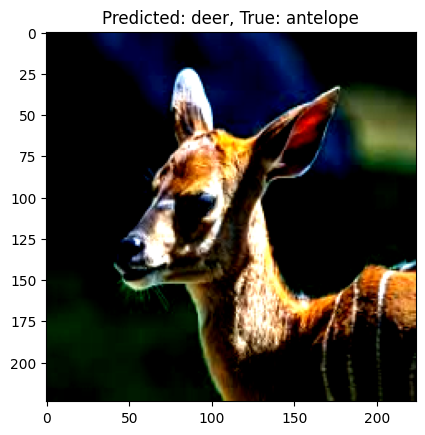

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


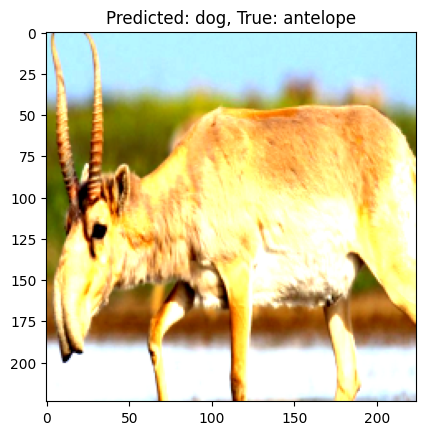

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


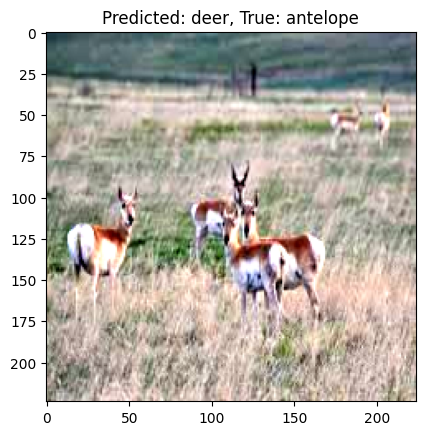

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


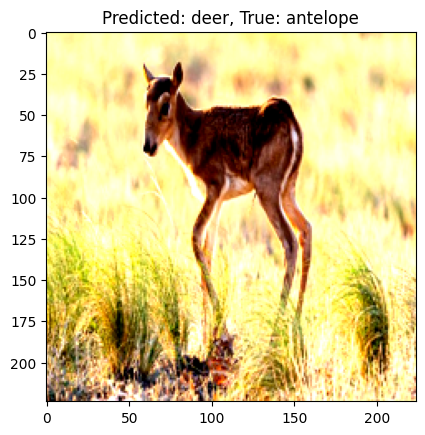

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


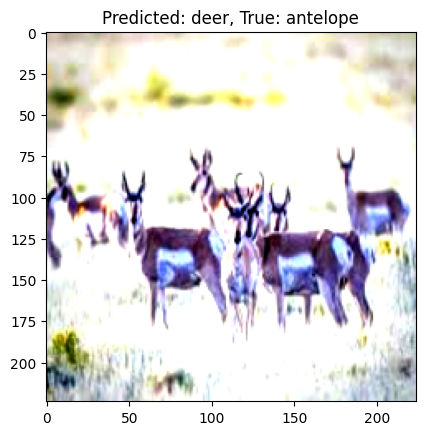

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


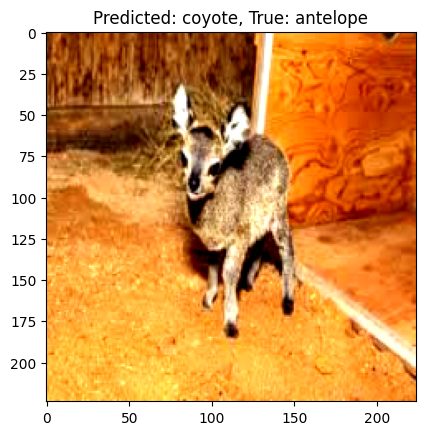

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


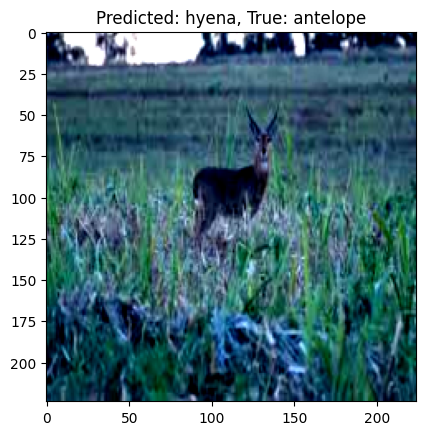

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


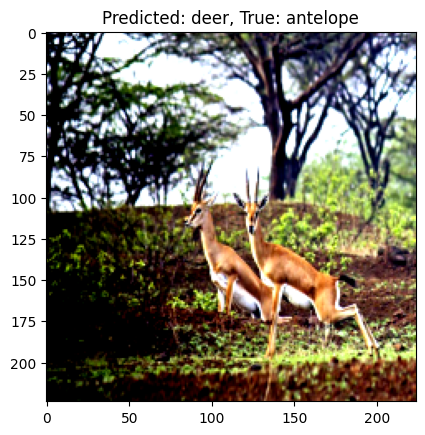

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


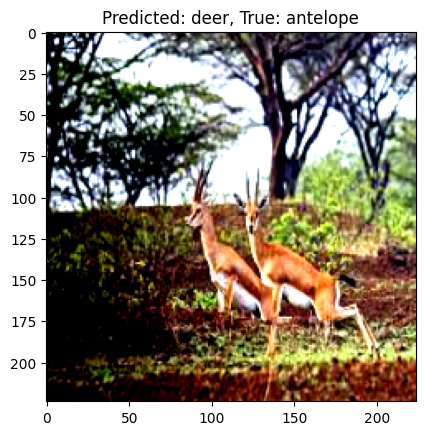

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


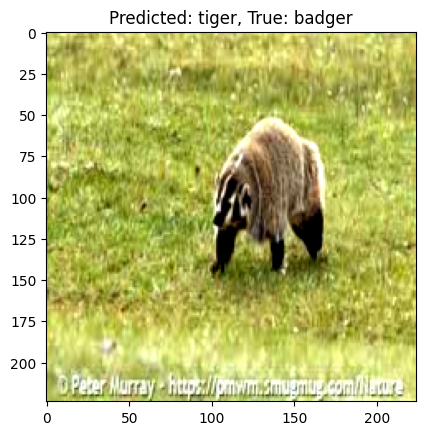

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


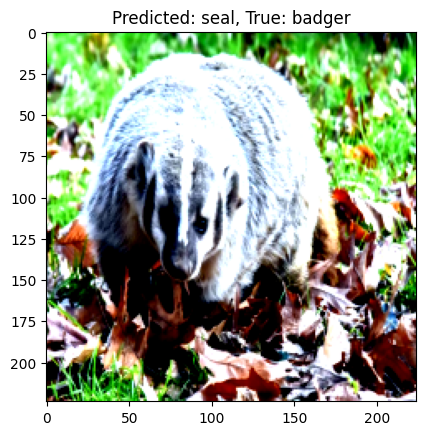

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


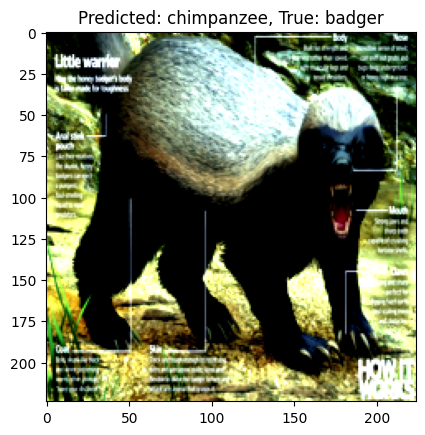

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


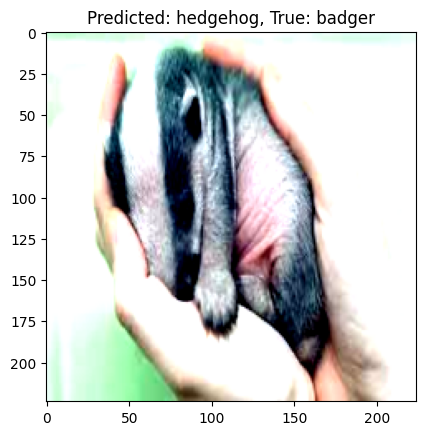

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


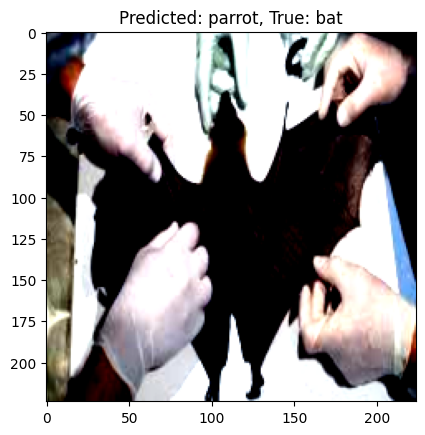

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


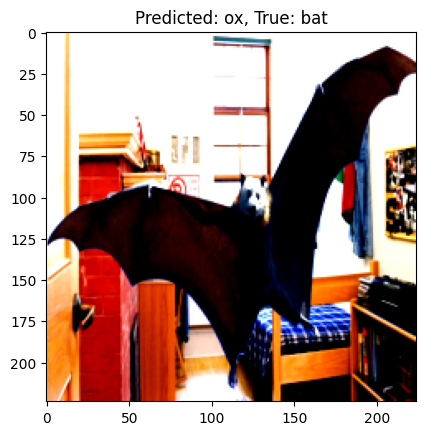

In [ ]:
def imshow(img, title=None):
    img = img / 2 + 0.5 
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    if title:
        plt.title(title)
    plt.show()

num_images_to_display = 15  
for i in range(min(num_images_to_display, len(incorrectly_classified))):
    img, pred, true = incorrectly_classified[i]
    imshow(img, title=f'Predicted: {species_folders[pred]}, True: {species_folders[true]}')


##### **Confusion Matrix**

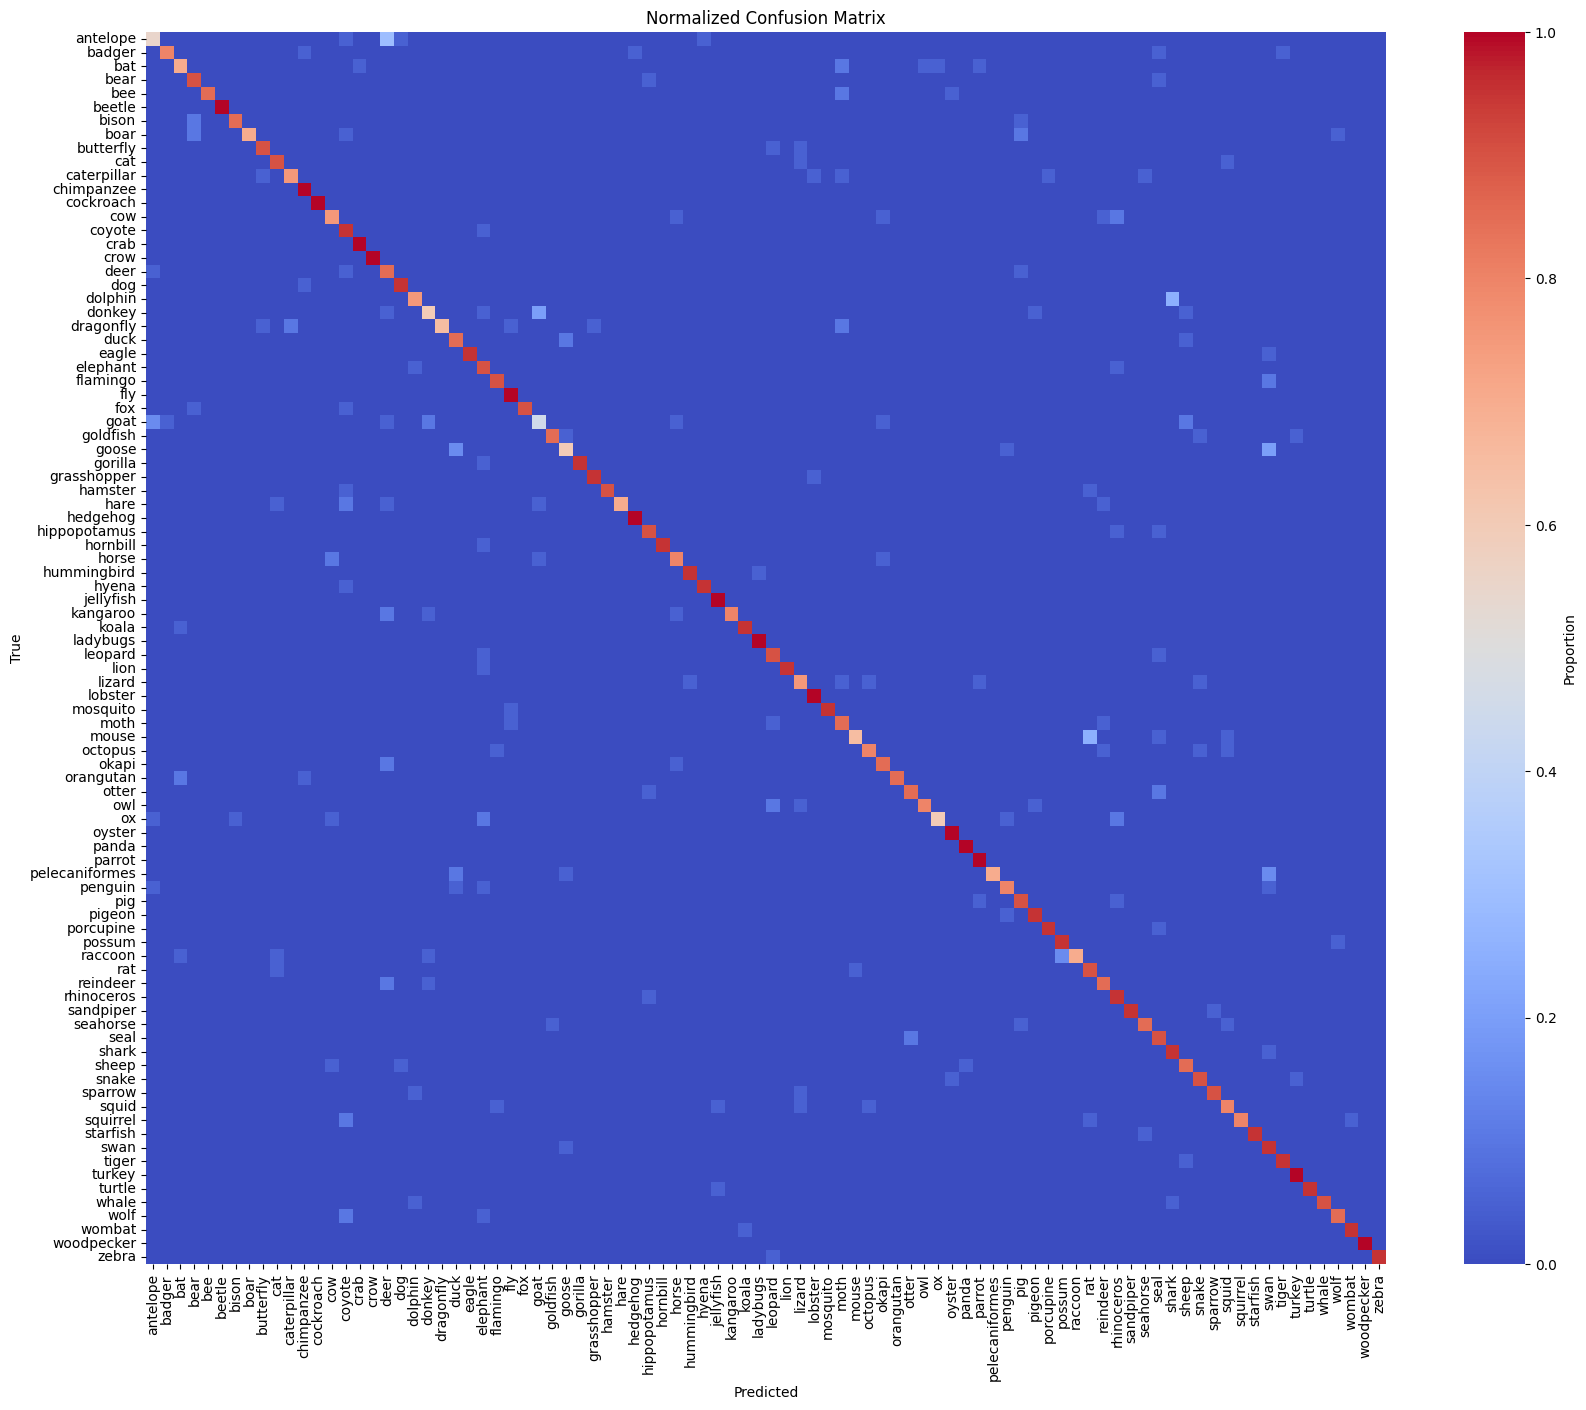

In [ ]:

model = models.resnet50(weights='IMAGENET1K_V1')
num_ftrs = model.fc.in_features  
model.fc = torch.nn.Linear(num_ftrs, num_labels)  
model.load_state_dict(torch.load('/Users/macbookpro/Desktop/mlproject/best_model_fold2.pth'))
model = model.to(device)
model.eval()

def compute_confusion_matrix(model, dataloader, device):
    model.eval()  
    all_preds = []
    all_labels = []
    
    with torch.no_grad():  
        for images, labels in dataloader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    
    return confusion_matrix(all_labels, all_preds)

def plot_confusion_matrix(cm, class_names):
    plt.figure(figsize=(20, 16))  
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]  
    sns.heatmap(cm_normalized, cmap='coolwarm', xticklabels=class_names, yticklabels=class_names, cbar_kws={'label': 'Proportion'})
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.title('Normalized Confusion Matrix')
    plt.xticks(rotation=90)  
    plt.yticks(rotation=0)  
    plt.show()


cm = compute_confusion_matrix(model, test_loader, device)

plot_confusion_matrix(cm, species_folders)


##### **Most common misclassifications**

In [ ]:

def find_most_common_misclassifications(cm, class_names):
    for i, row in enumerate(cm):
        row[i] = 0 
        most_common_misclassification = np.argmax(row)
        print(f"{class_names[i]} was most commonly misclassified as {class_names[most_common_misclassification]}")


cm = compute_confusion_matrix(model, test_loader, device)


find_most_common_misclassifications(cm, species_folders)


antelope was most commonly misclassified as deer
badger was most commonly misclassified as chimpanzee
bat was most commonly misclassified as moth
bear was most commonly misclassified as hippopotamus
bee was most commonly misclassified as moth
beetle was most commonly misclassified as antelope
bison was most commonly misclassified as bear
boar was most commonly misclassified as bear
butterfly was most commonly misclassified as leopard
cat was most commonly misclassified as lizard
caterpillar was most commonly misclassified as butterfly
chimpanzee was most commonly misclassified as antelope
cockroach was most commonly misclassified as antelope
cow was most commonly misclassified as rhinoceros
coyote was most commonly misclassified as elephant
crab was most commonly misclassified as antelope
crow was most commonly misclassified as antelope
deer was most commonly misclassified as antelope
dog was most commonly misclassified as chimpanzee
dolphin was most commonly misclassified as shark
don

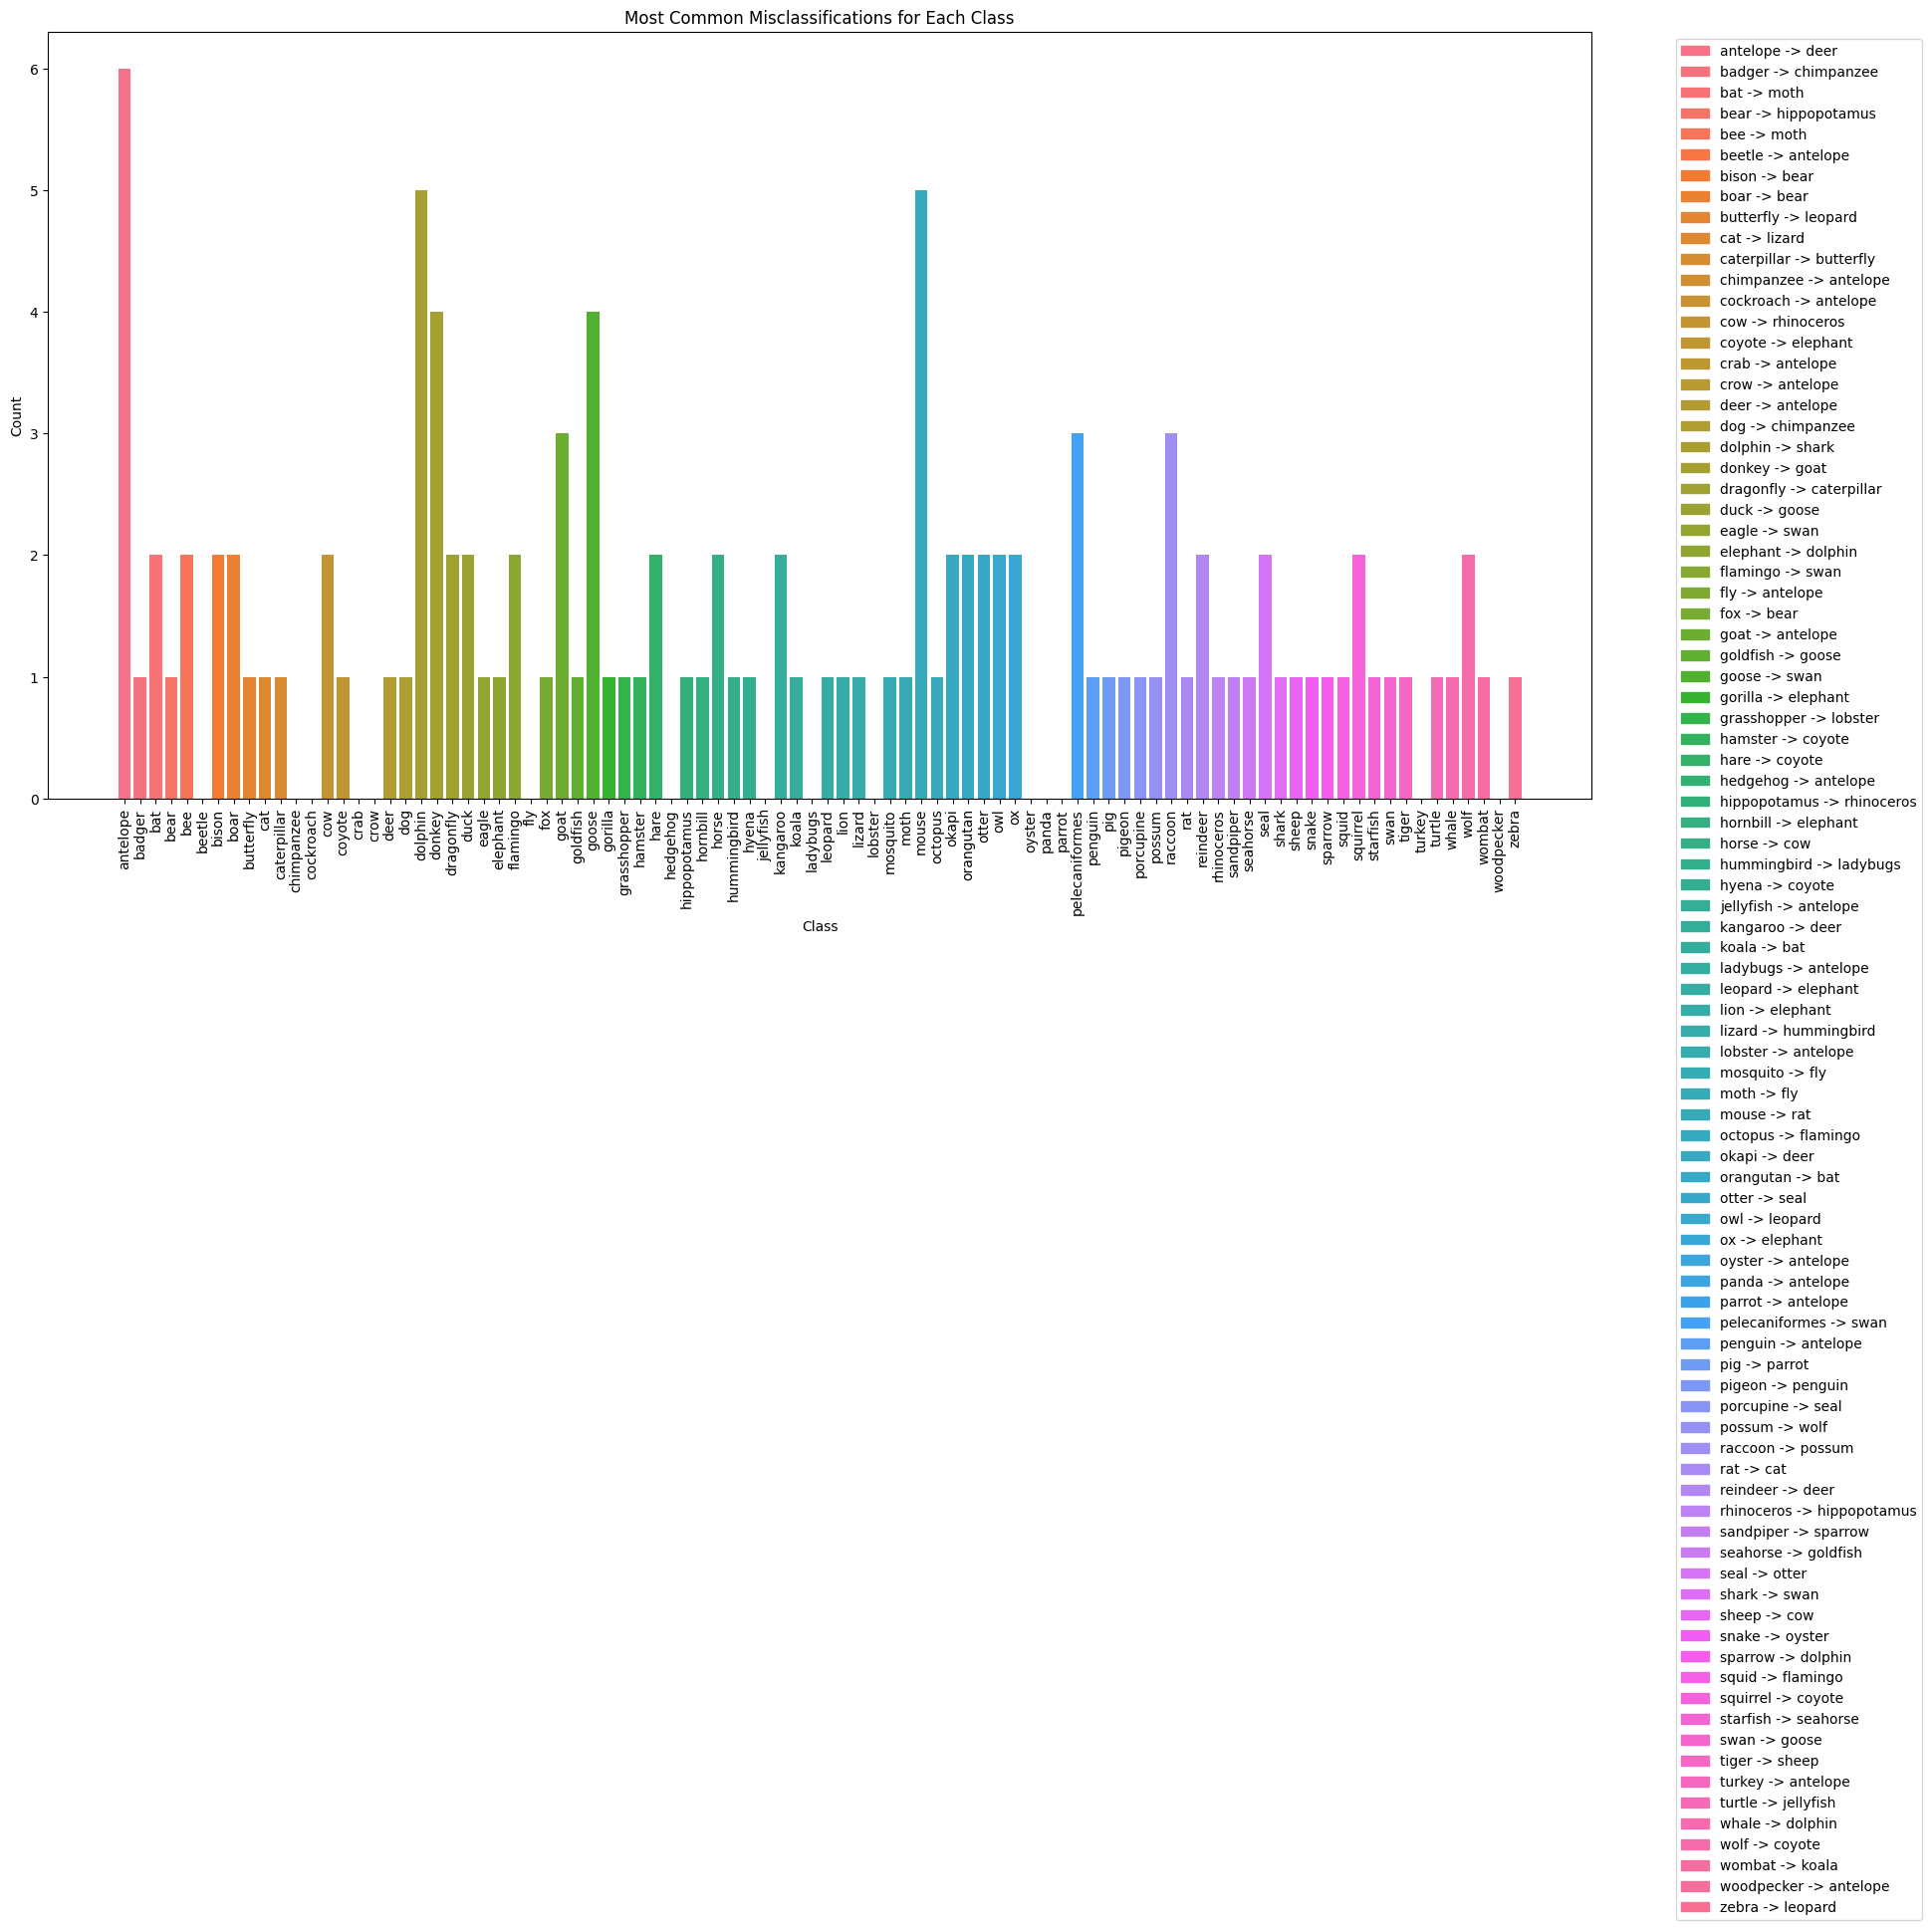

In [ ]:

def plot_misclassifications_legend(misclassification_data):
    df = pd.DataFrame(misclassification_data, columns=['True Label', 'Predicted Label', 'Count'])

    unique_misclassifications = df[['True Label', 'Predicted Label']].apply(lambda x: f"{x[0]} -> {x[1]}", axis=1).unique()
    palette = sns.color_palette("husl", len(unique_misclassifications))
    color_dict = dict(zip(unique_misclassifications, palette))
    

    df['Color'] = df[['True Label', 'Predicted Label']].apply(lambda x: color_dict[f"{x[0]} -> {x[1]}"], axis=1)
    
    plt.figure(figsize=(20, 10))
    bars = plt.bar(df.index, df['Count'], color=df['Color'])
    
    legend_labels = [f"{row['True Label']} -> {row['Predicted Label']}" for idx, row in df.iterrows()]
    unique_legend_labels = list(dict.fromkeys(legend_labels))  # Remove duplicates while preserving order
    handles = [plt.Rectangle((0,0),1,1, color=color_dict[label]) for label in unique_legend_labels]
    
    plt.legend(handles, unique_legend_labels, bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.xlabel('Class')
    plt.ylabel('Count')
    plt.title('Most Common Misclassifications for Each Class')
    plt.xticks(df.index, df['True Label'], rotation=90)
    plt.show()

cm = compute_confusion_matrix(model, test_loader, device)


misclassification_data = find_most_common_misclassifications(cm, species_folders)
plot_misclassifications_legend(misclassification_data)


## **Section 4: Image Transformers**

The Vision Transformer (ViT) represents a **paradigm shift in image processing**, leveraging the power of transformers, which have revolutionized natural language processing. Introduced by Dosovitskiy et al., ViT applies transformer architectures **directly to sequences of image patches**, bypassing traditional convolutional neural networks.

### **Section 4.1: First Image Transformer = ViT**


In our first trials, we were using many more folds and epochs in training our model to get optimal and more significative results.
But, **unfortunately**, given the limited means we have to run it, we had to reduce these numbers to the minimum in order to manage to get results. While we know that these aren't the best possible outcomes, we still believe the results are significant and interesting to check out!

In [ ]:

class AnimalDataset(torch.utils.data.Dataset):
    def __init__(self, images_with_labels, image_size=224, transform=None):
        self.images_with_labels = images_with_labels
        self.image_size = image_size
        self.transform = transform

    def __len__(self):
        return len(self.images_with_labels)

    def __getitem__(self, idx):
        image_path, label = self.images_with_labels[idx]
        image = Image.open(image_path)
        if self.transform:
            image = self.transform(image)
        return image, label

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])



#### **Section 4.1.1: ViT Not Augmented**


In [ ]:

train_dataset = AnimalDataset(images_with_labels_train, transform=train_transform)
test_dataset = AnimalDataset(images_with_labels_test, transform=test_transform)


model_name = "google/vit-base-patch16-224-in21k"
processor = ViTImageProcessor.from_pretrained(model_name)
num_labels = len(species_folders)  
num_epochs = 2
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
patience = 3
k = 3 
kf = KFold(n_splits=k, shuffle=True, random_state=42)

# Cross-Validation Loop
for fold, (train_idx, val_idx) in enumerate(kf.split(images_with_labels_train)):
    print(f"Fold {fold + 1}/{k}")

    train_fold = Subset(train_dataset, train_idx)
    val_fold = Subset(train_dataset, val_idx)
    
    train_loader = DataLoader(train_fold, batch_size=32, shuffle=True)
    val_loader = DataLoader(val_fold, batch_size=32)

    test_loader = DataLoader(test_dataset, batch_size=32)

    
    model = ViTForImageClassification.from_pretrained(model_name, num_labels=num_labels).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)

    # Early Stopping Initialization
    best_val_loss = float('inf')
    epochs_without_improvement = 0

    # Training and Validation (with Early Stopping)
    for epoch in range(num_epochs):
        model.train()
        train_loss = 0.0
        for images, labels in tqdm(train_loader, desc=f"Epoch {epoch + 1}/{num_epochs}"):
            images, labels = images.to(device), labels.to(device)
            outputs = model(pixel_values=images, labels=labels) 
            loss = outputs.loss
            train_loss += loss.item()
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
        print(f"Epoch {epoch + 1}/{num_epochs}, Train Loss: {train_loss / len(train_loader)}")

        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)

                outputs = model(pixel_values=images, labels=labels)
                loss = outputs.loss  
                val_loss += loss.item() 

        val_loss /= len(val_loader)

        
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), f'best_model_fold{fold + 1}.pth')
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= patience:
                print("Early stopping!")
                break  

        print(f"Epoch {epoch + 1}/{num_epochs}, Val Loss: {val_loss / len(val_loader):.4f}")

    model.load_state_dict(torch.load(f'best_model_fold{fold + 1}.pth'))

    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(pixel_values=images)
            _, predicted = torch.max(outputs.logits, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    print(f"Test Accuracy: {100 * correct / total:.2f}%")


/home/default/Desktop/venv/lib/python3.8/site-packages/torch/cuda/__init__.py:118: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 11040). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at ../c10/cuda/CUDAFunctions.cpp:108.)
  return torch._C._cuda_getDeviceCount() > 0


Fold 1/3


Some weights of ViTForImageClassification were not initialized from the model checkpoint at google/vit-base-patch16-224-in21k and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Epoch 1/2: 100%|██████████| 75/75 [16:00<00:00, 12.81s/it]


Epoch 1/2, Train Loss: 4.03127877553304
Epoch 1/2, Val Loss: 0.0909


Epoch 2/2: 100%|██████████| 75/75 [15:27<00:00, 12.36s/it]


...

Some weights of ViTForImageClassification were not initialized from the model checkpoint at google/vit-base-patch16-224-in21k and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Epoch 1/2: 100%|██████████| 75/75 [16:18<00:00, 13.04s/it]


Epoch 1/2, Train Loss: 4.004218947092692
Epoch 1/2, Val Loss: 0.0896


Epoch 2/2: 100%|██████████| 75/75 [16:23<00:00, 13.11s/it]


Epoch 2/2, Train Loss: 2.744331143697103
Epoch 2/2, Val Loss: 0.0609
Test Accuracy: 96.72%


Bad pipe message: %s [b'\x9a\x96\x99\xc1\xbf|\xc0\x9cm:e\xe7\xfe\xa0bH\xa9[ \xc1 h\xd2.Y"\x92\xe3\xbe_0Pb:\xd9\x92\x03\x1e4\x08\xef\xe3z@\\y\xe6A\x16\xdc\x91\x00\x08\x13\x02\x13\x03\x13\x01\x00\xff\x01\x00\x00\x8f\x00\x00\x00\x0e\x00\x0c\x00\x00\t127.0.0.1\x00\x0b\x00\x04\x03\x00\x01', b'\n']
Bad pipe message: %s [b'\x9c\x02\x0e\x0f1\x8e\xa5\xdd\x88/\xb5f&\xb2%%\xbe\x90\x00\x00\xa6', b"\xc00\x00\xa3\x00\x9f\xcc\xa9\xcc\xa8\xcc\xaa\xc0\xaf\xc0\xad\xc0\xa3\xc0\x9f\xc0]\xc0a\xc0W\xc0S\xc0+\xc0/\x00\xa2\x00\x9e\xc0\xae\xc0\xac\xc0\xa2\xc0\x9e\xc0\\\xc0`\xc0V\xc0R\xc0$\xc0(\x00k\x00j\xc0s\xc0w\x00\xc4\x00\xc3\xc0#\xc0'\x00g\x00@\xc0r\xc0v\x00\xbe\x00\xbd\xc0\n\xc0\x14\x009\x008\x00\x88\x00\x87\xc0\t\xc0\x13\x003\x002\x00\x9a\x00\x99\x00E\x00D\xc0\x07\xc0\x11\xc0\x08\xc0\x12\x00\x16\x00\x13\x00\x9d\xc0\xa1\xc0\x9d\xc0Q\x00\x9c\xc0\xa0\xc0\x9c\xc0P\x00=\x00\xc0\x00<\x00\xba\x005\x00\x84\x00/\x00\x96\x00A\x00\x05\x00\n\x00\xff\x01\x00\x00j\x00\x00\x00\x0e\x00\x0c\x00\x00\t127.0.0.1\x00\x0b\x00


#### **Section 4.1.2: ViT Augmented**

In [ ]:
train_dataset = AnimalDataset(images_with_labels_augmented_train, transform=train_transform)
test_dataset = AnimalDataset(images_with_labels_test, transform=test_transform)

model_name = "google/vit-base-patch16-224-in21k"
processor = ViTImageProcessor.from_pretrained(model_name)
num_labels = len(species_folders)
num_epochs = 2
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
patience = 3  
k = 3  
kf = KFold(n_splits=k, shuffle=True, random_state=42)


for fold, (train_idx, val_idx) in enumerate(kf.split(images_with_labels_augmented_train)):
    print(f"Fold {fold + 1}/{k}")

    train_fold = Subset(train_dataset, train_idx)
    val_fold = Subset(train_dataset, val_idx)
    
    train_loader = DataLoader(train_fold, batch_size=32, shuffle=True)
    val_loader = DataLoader(val_fold, batch_size=32)

    test_loader = DataLoader(test_dataset, batch_size=32)

   
    model = ViTForImageClassification.from_pretrained(model_name, num_labels=num_labels).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)

    # Early Stopping Initialization
    best_val_loss = float('inf')
    epochs_without_improvement = 0

    # Training and Validation (with Early Stopping)
    for epoch in range(num_epochs):
        model.train()
        train_loss = 0.0
        for images, labels in tqdm(train_loader, desc=f"Epoch {epoch + 1}/{num_epochs}"):
            images, labels = images.to(device), labels.to(device)
            outputs = model(pixel_values=images, labels=labels) 
            loss = outputs.loss
            train_loss += loss.item()
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
        print(f"Epoch {epoch + 1}/{num_epochs}, Train Loss: {train_loss / len(train_loader)}")

        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)

                outputs = model(pixel_values=images, labels=labels)
                loss = outputs.loss  
                val_loss += loss.item()  

        val_loss /= len(val_loader)

        
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), f'best_model_fold{fold + 1}.pth')
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= patience:
                print("Early stopping!")
                break  

        print(f"Epoch {epoch + 1}/{num_epochs}, Val Loss: {val_loss / len(val_loader):.4f}")

    model.load_state_dict(torch.load(f'best_model_fold{fold + 1}.pth'))

    
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(pixel_values=images)
            _, predicted = torch.max(outputs.logits, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    print(f"Test Accuracy: {100 * correct / total:.2f}%")


Fold 1/3


Some weights of ViTForImageClassification were not initialized from the model checkpoint at google/vit-base-patch16-224-in21k and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Epoch 1/2: 100%|██████████| 450/450 [1:40:43<00:00, 13.43s/it]


Epoch 1/2, Train Loss: 2.141284305850665
Epoch 1/2, Val Loss: 0.0029


Epoch 2/2: 100%|██████████| 450/450 [1:38:42<00:00, 13.16s/it]


Epoch 2/2, Train Loss: 0.30079002236326535
Epoch 2/2, Val Loss: 0.0017
Test Accuracy: 96.50%
Fold 2/3


...

Epoch 2/2, Train Loss: 0.30533483540018397
Epoch 2/2, Val Loss: 0.0013
Test Accuracy: 96.44%
Fold 3/3


Some weights of ViTForImageClassification were not initialized from the model checkpoint at google/vit-base-patch16-224-in21k and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Epoch 1/2: 100%|██████████| 450/450 [1:36:06<00:00, 12.81s/it]


Epoch 1/2, Train Loss: 2.1703145987457697
Epoch 1/2, Val Loss: 0.0032


Epoch 2/2: 100%|██████████| 450/450 [1:35:51<00:00, 12.78s/it]


Epoch 2/2, Train Loss: 0.3122386381857925
Epoch 2/2, Val Loss: 0.0019
Test Accuracy: 95.67%


If we take the average of the folds, we can see a slight **increase in performance** in the model after training it **with augmented data**!!


#### **Section 4.1.3:  ViT Augmented Further analysis**


For the same reasons of previous models, we proceed with an analysis.

##### **Misclassified Images**

In [ ]:

incorrectly_classified = []
model.eval()
correct = 0
total = 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(pixel_values=images)
        _, predicted = torch.max(outputs.logits, 1)
        
        
        for i in range(len(labels)):
            if predicted[i] != labels[i]:
                incorrectly_classified.append((images[i].cpu(), predicted[i].cpu(), labels[i].cpu()))

print(f"Number of incorrectly classified images: {len(incorrectly_classified)}")


Number of incorrectly classified images: 78


78 of Vit **Vs** 232 of CNN , a big improvement for sure!

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


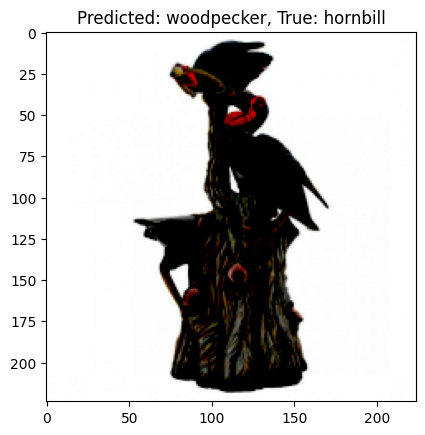

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


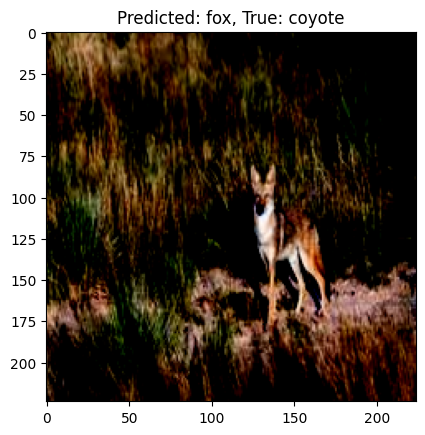

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


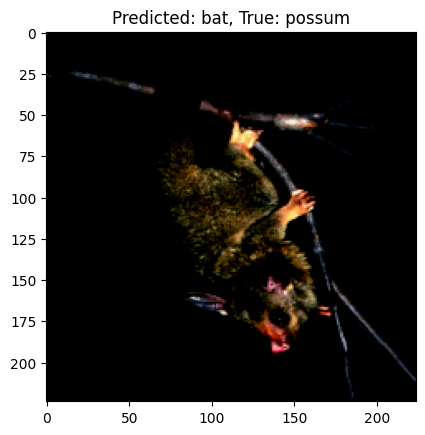

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


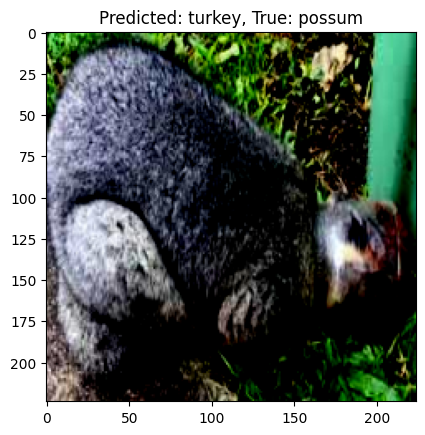

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


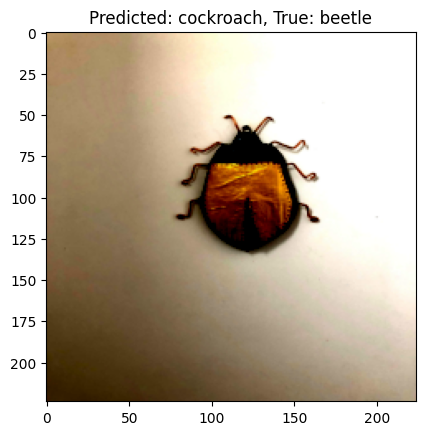

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


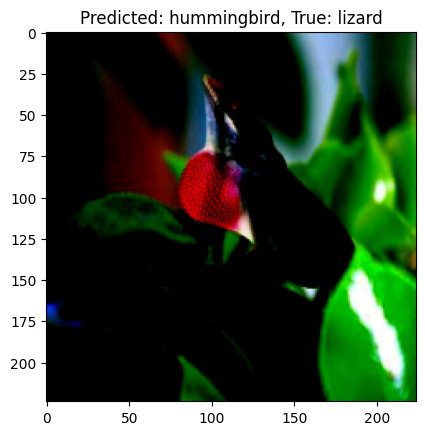

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


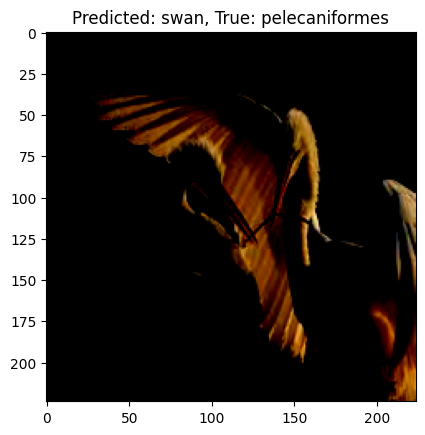

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


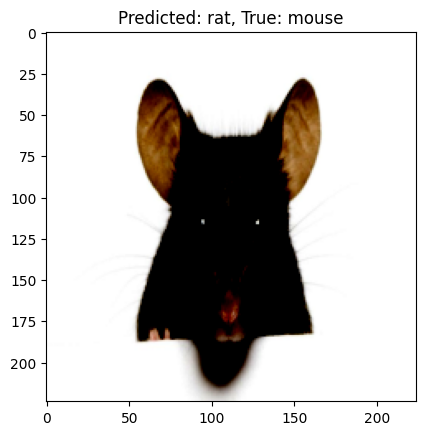

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


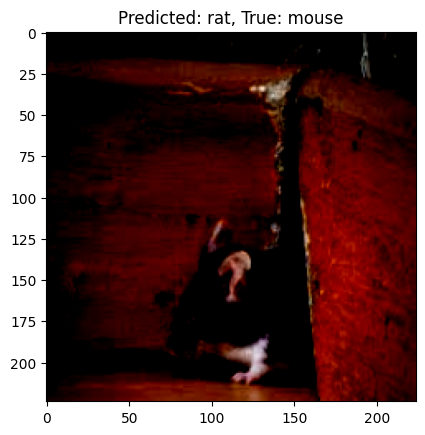

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


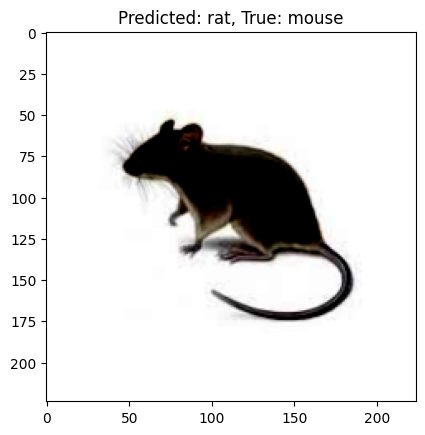

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


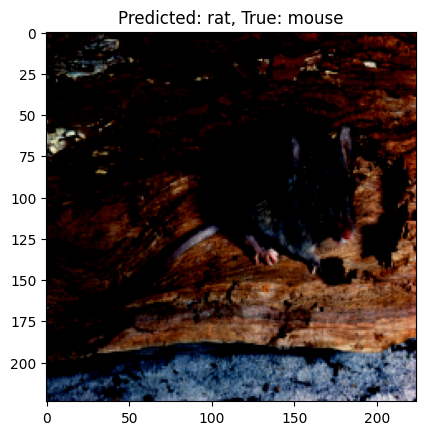

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


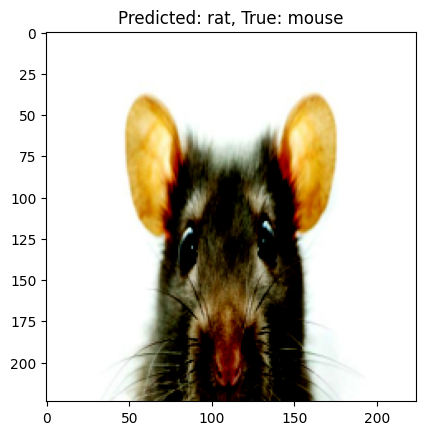

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


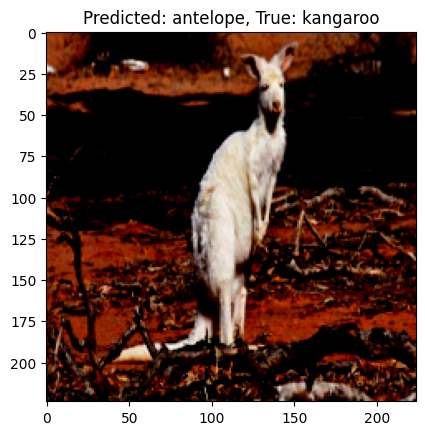

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


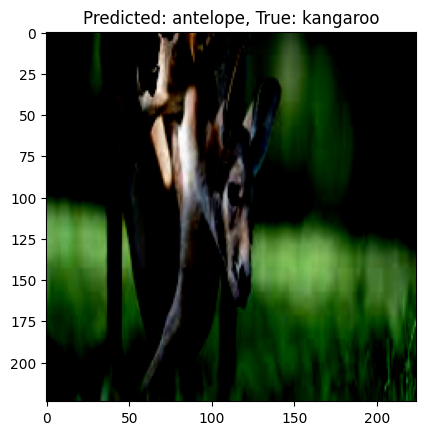

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


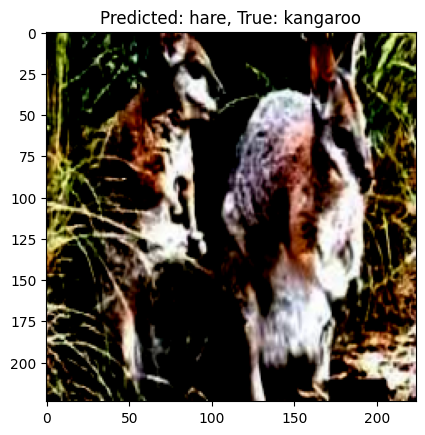

In [ ]:
def imshow(img, title=None):
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    if title:
        plt.title(title)
    plt.show()

num_images_to_display = 15 
for i in range(min(num_images_to_display, len(incorrectly_classified))):
    img, pred, true = incorrectly_classified[i]
    imshow(img, title=f'Predicted: {species_folders[pred]}, True: {species_folders[true]}')

##### **Confusion Matrix**

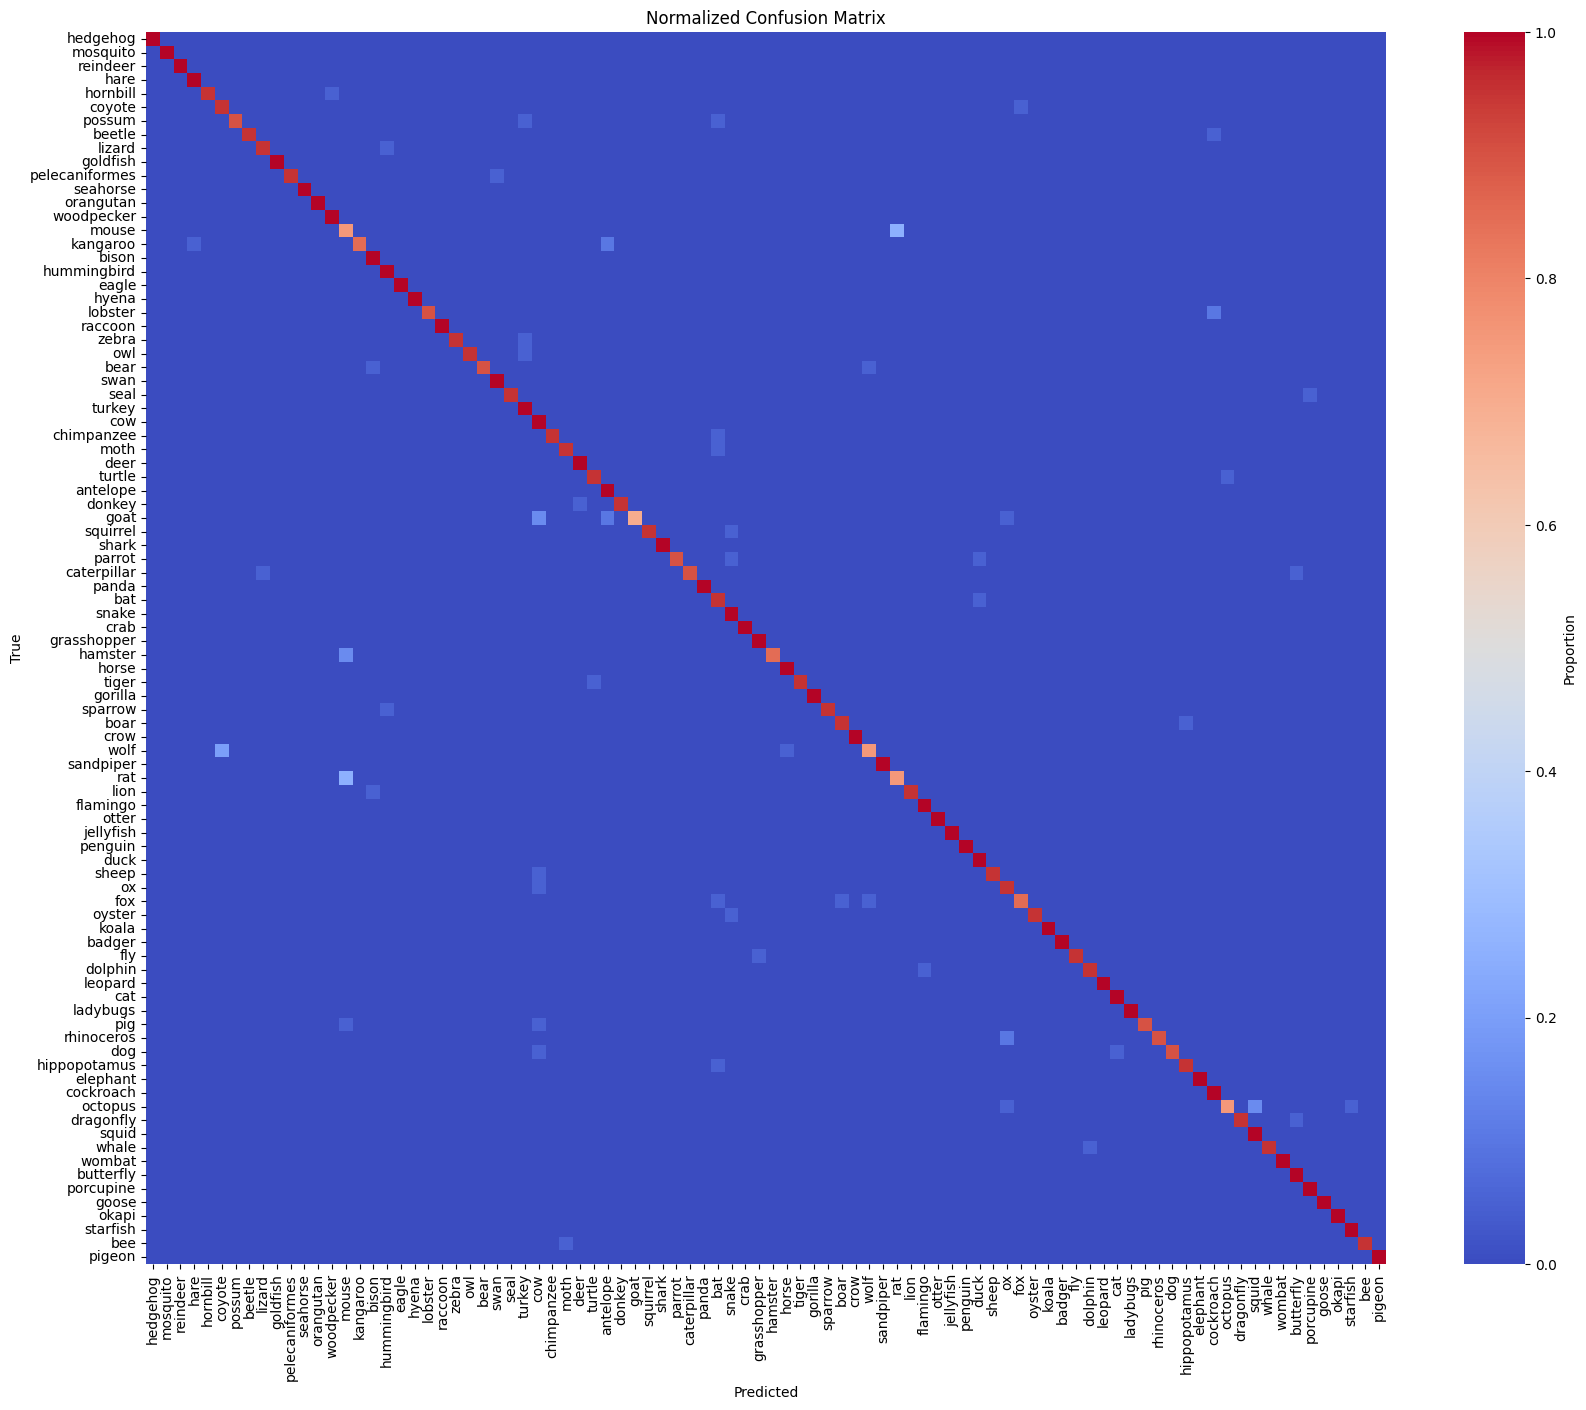

In [ ]:

def compute_confusion_matrix(model, dataloader, device):
    model.eval()  
    all_preds = []
    all_labels = []

    with torch.no_grad():  
        for images, labels in dataloader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(pixel_values=images)  # Pass images through the ViT model
            _, predicted = torch.max(outputs.logits, 1)  # Get the class with the highest probability

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    return confusion_matrix(all_labels, all_preds)


def plot_confusion_matrix(cm, class_names):
    plt.figure(figsize=(20, 16))  
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]  
    sns.heatmap(cm_normalized, cmap='coolwarm', xticklabels=class_names, yticklabels=class_names, cbar_kws={'label': 'Proportion'})
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.title('Normalized Confusion Matrix')
    plt.xticks(rotation=90)  
    plt.yticks(rotation=0)  
    plt.show()

cm = compute_confusion_matrix(model, test_loader, device)
plot_confusion_matrix(cm, species_folders)

##### **Most Common Misclassification**

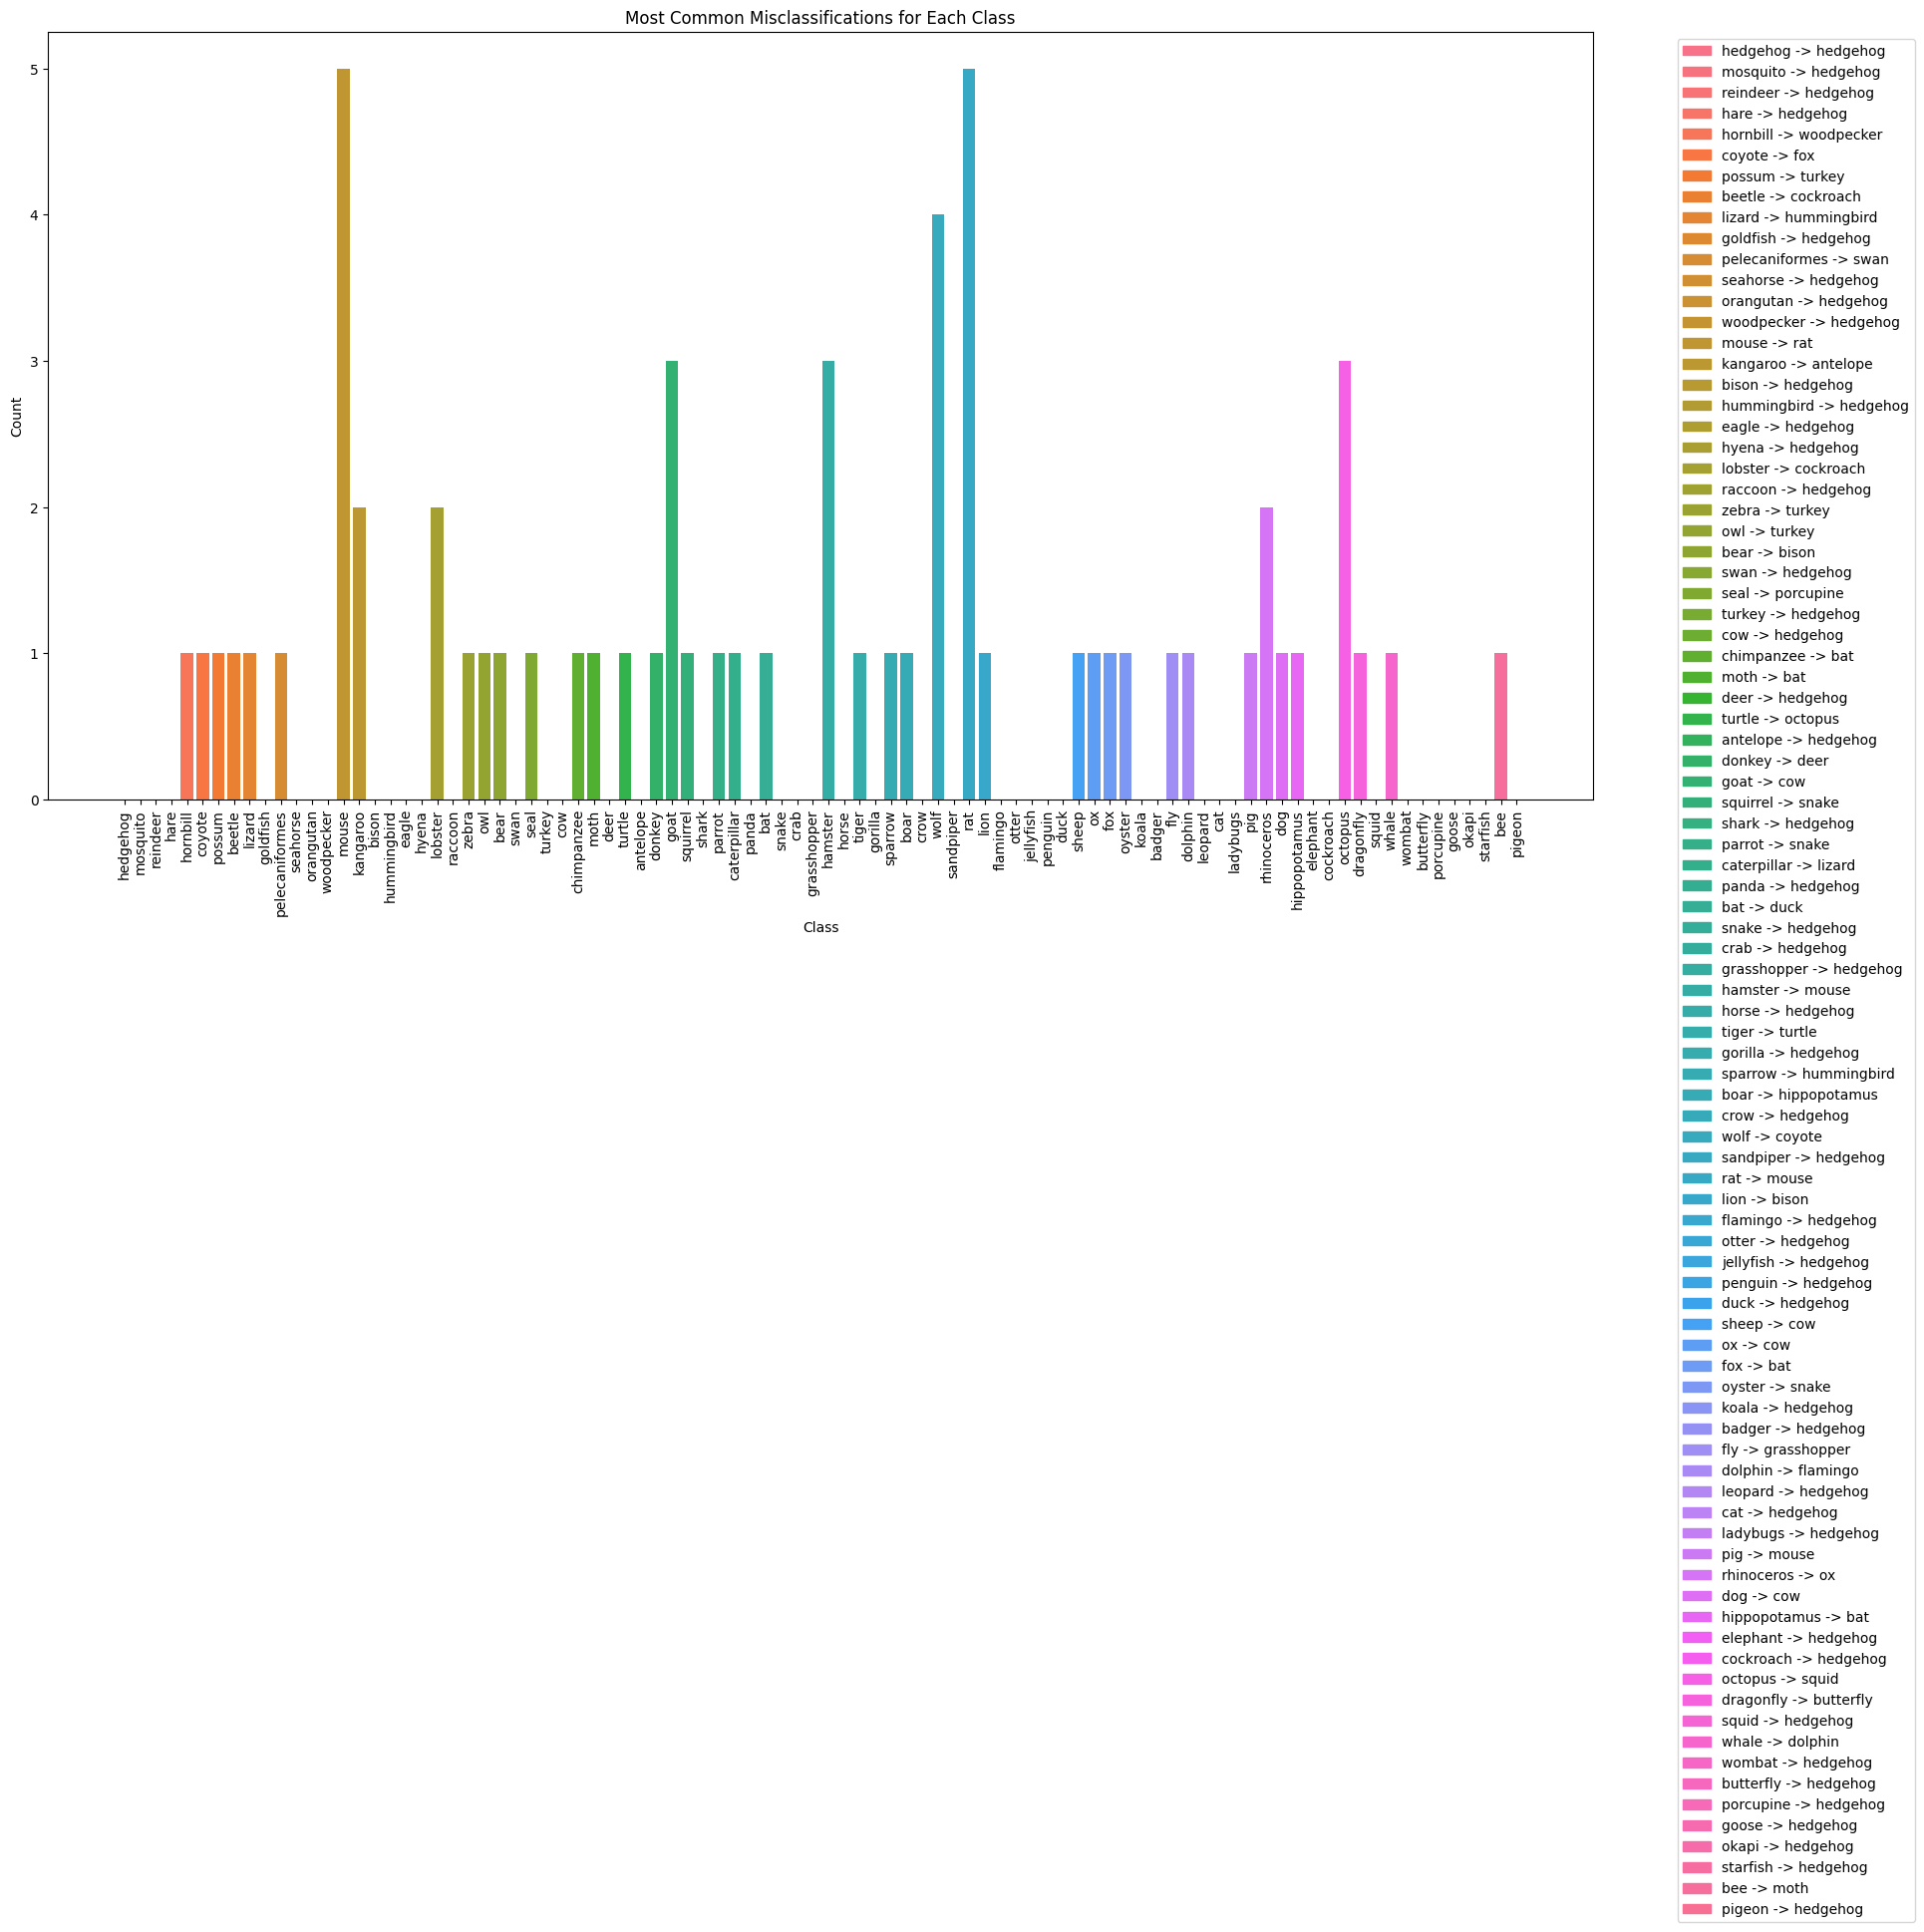

In [ ]:

def find_most_common_misclassifications(cm, class_names):
    misclassification_data = []
    for i, row in enumerate(cm):
        row[i] = 0  # Exclude correct classifications
        most_common_misclassification = np.argmax(row)
        misclassification_data.append((class_names[i], class_names[most_common_misclassification], row[most_common_misclassification]))
    return misclassification_data

def plot_misclassifications_legend(misclassification_data):
    df = pd.DataFrame(misclassification_data, columns=['True Label', 'Predicted Label', 'Count'])
    

    unique_misclassifications = df[['True Label', 'Predicted Label']].apply(lambda x: f"{x[0]} -> {x[1]}", axis=1).unique()
    palette = sns.color_palette("husl", len(unique_misclassifications))
    color_dict = dict(zip(unique_misclassifications, palette))

    df['Color'] = df[['True Label', 'Predicted Label']].apply(lambda x: color_dict[f"{x[0]} -> {x[1]}"], axis=1)
    
    plt.figure(figsize=(20, 10))
    bars = plt.bar(df.index, df['Count'], color=df['Color'])

    legend_labels = [f"{row['True Label']} -> {row['Predicted Label']}" for idx, row in df.iterrows()]
    unique_legend_labels = list(dict.fromkeys(legend_labels))  # Remove duplicates while preserving order
    handles = [plt.Rectangle((0,0),1,1, color=color_dict[label]) for label in unique_legend_labels]
    
    plt.legend(handles, unique_legend_labels, bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.xlabel('Class')
    plt.ylabel('Count')
    plt.title('Most Common Misclassifications for Each Class')
    plt.xticks(df.index, df['True Label'], rotation=90)
    plt.show()

cm = compute_confusion_matrix(model, test_loader, device)

misclassification_data = find_most_common_misclassifications(cm, species_folders)
plot_misclassifications_legend(misclassification_data)


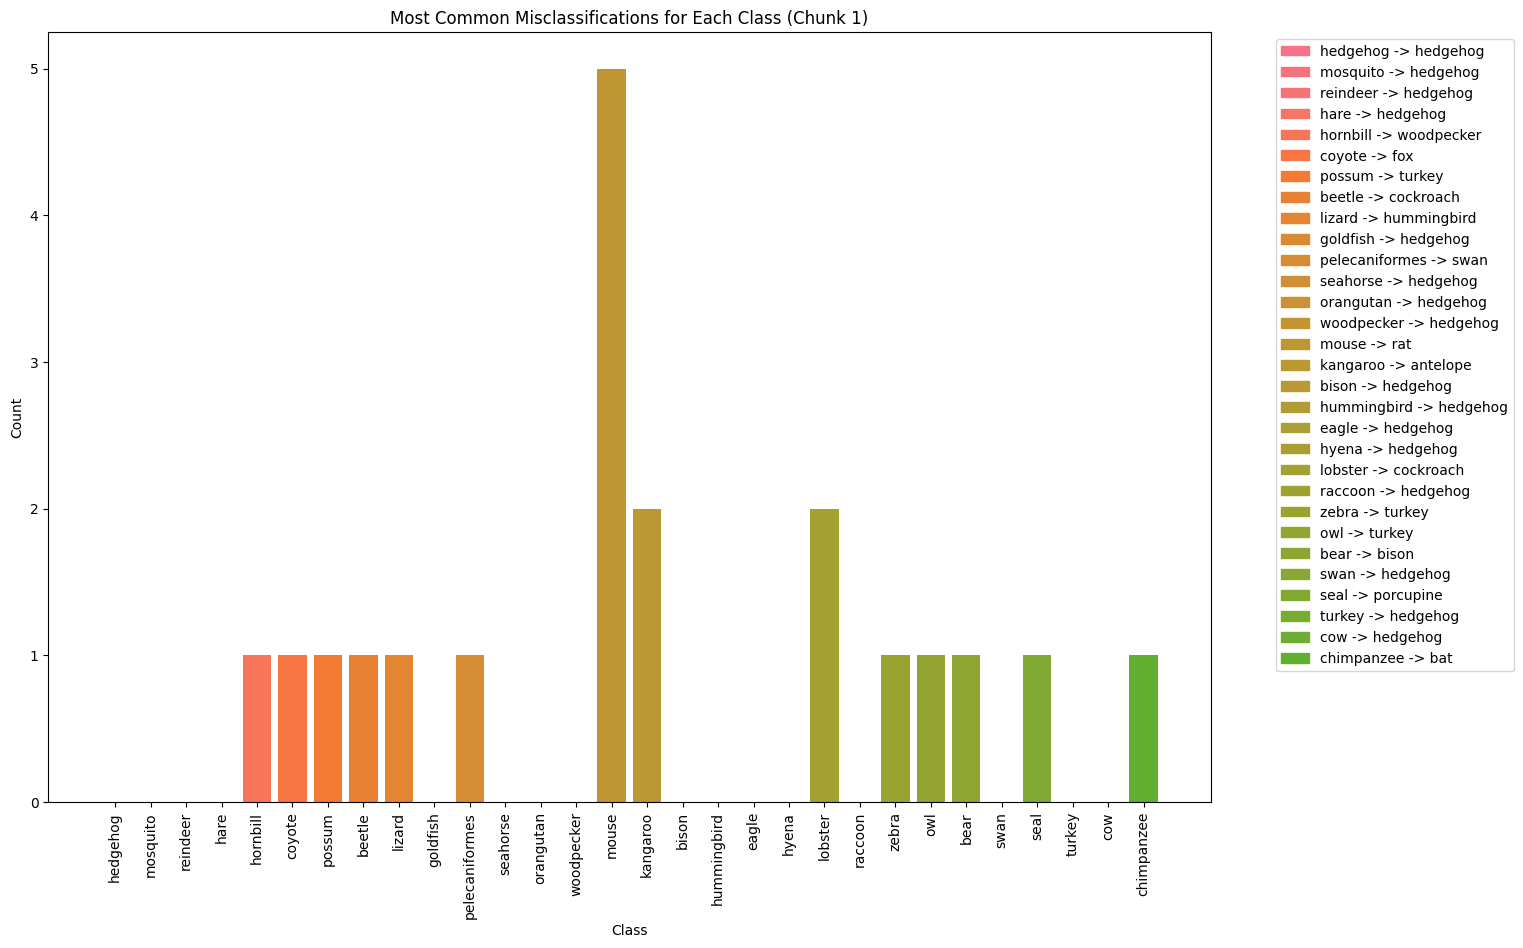

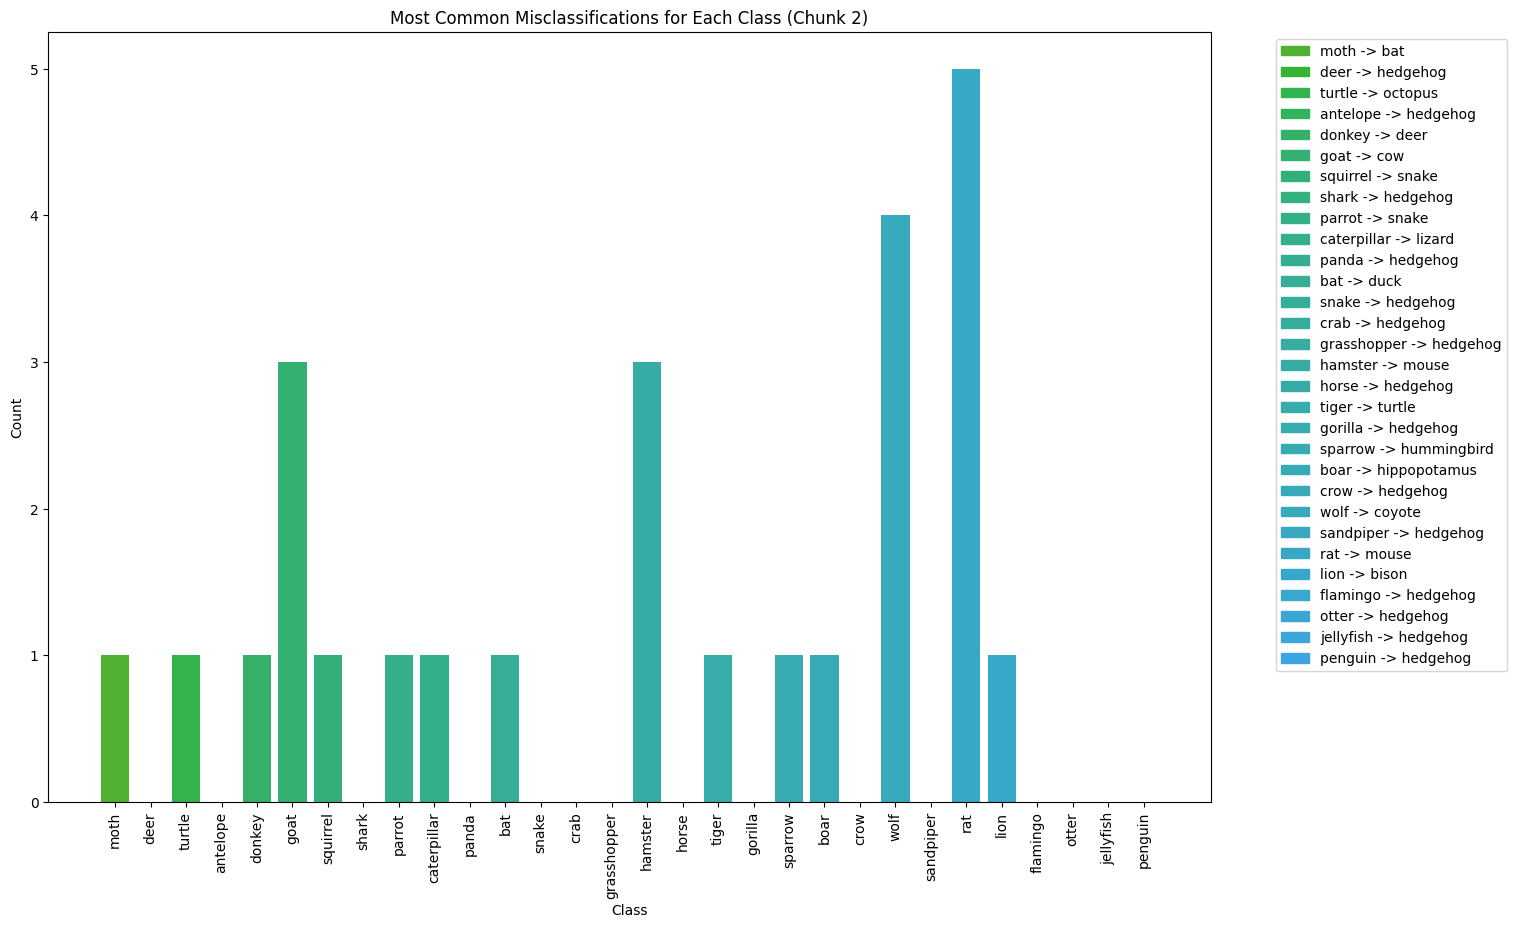

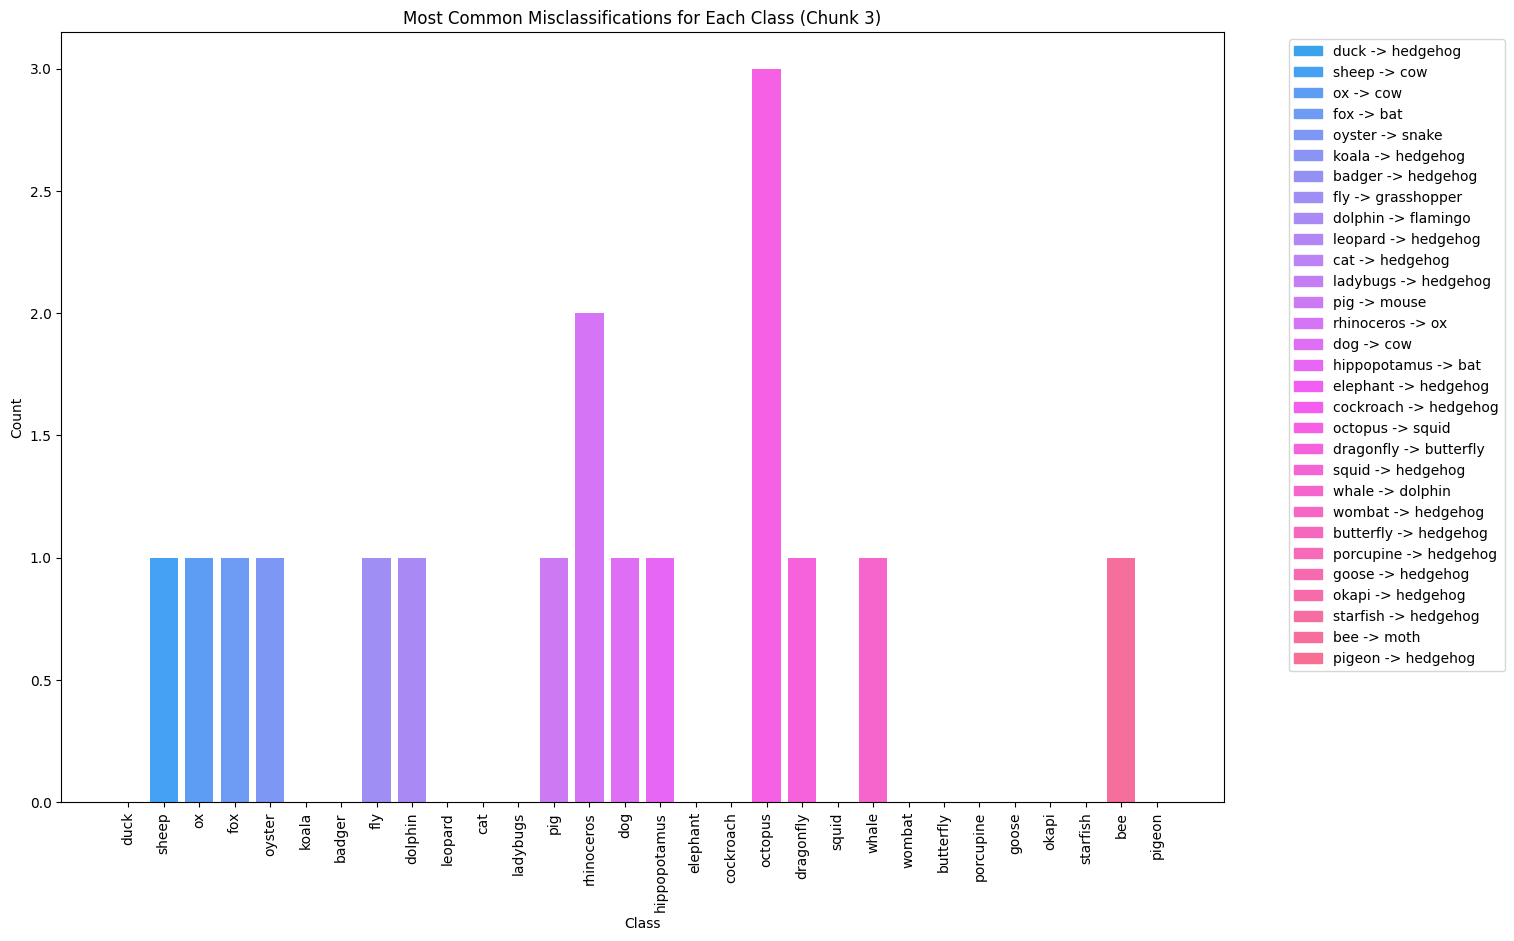

In [ ]:

def find_most_common_misclassifications(cm, class_names):
    misclassification_data = []
    for i, row in enumerate(cm):
        row[i] = 0  # Exclude correct classifications
        most_common_misclassification = np.argmax(row)
        misclassification_data.append((class_names[i], class_names[most_common_misclassification], row[most_common_misclassification]))
    return misclassification_data


def plot_misclassifications_chunks(misclassification_data, chunk_size=30):
    df = pd.DataFrame(misclassification_data, columns=['True Label', 'Predicted Label', 'Count'])
    unique_misclassifications = df[['True Label', 'Predicted Label']].apply(lambda x: f"{x[0]} -> {x[1]}", axis=1).unique()
    palette = sns.color_palette("husl", len(unique_misclassifications))
    color_dict = dict(zip(unique_misclassifications, palette))
    
    df['Color'] = df[['True Label', 'Predicted Label']].apply(lambda x: color_dict[f"{x[0]} -> {x[1]}"], axis=1)
    
    num_chunks = int(np.ceil(len(df) / chunk_size))
    
    for i in range(num_chunks):
        chunk = df.iloc[i * chunk_size:(i + 1) * chunk_size]
        
        plt.figure(figsize=(15, 10))
        bars = plt.bar(chunk.index, chunk['Count'], color=chunk['Color'])

        legend_labels = [f"{row['True Label']} -> {row['Predicted Label']}" for idx, row in chunk.iterrows()]
        unique_legend_labels = list(dict.fromkeys(legend_labels))  # Remove duplicates while preserving order
        handles = [plt.Rectangle((0,0),1,1, color=color_dict[label]) for label in unique_legend_labels]
        
        plt.legend(handles, unique_legend_labels, bbox_to_anchor=(1.05, 1), loc='upper left')
        plt.xlabel('Class')
        plt.ylabel('Count')
        plt.title(f'Most Common Misclassifications for Each Class (Chunk {i + 1})')
        plt.xticks(chunk.index, chunk['True Label'], rotation=90)
        plt.show()


cm = compute_confusion_matrix(model, test_loader, device)
misclassification_data = find_most_common_misclassifications(cm, species_folders)
plot_misclassifications_chunks(misclassification_data, chunk_size=30)



### **Section 4.2: Second Image Transformer = Swin**

To conclude our study on Image Transformers with **clarity and comprehensiveness**, we have decided to include the code for Swin Transformer, despite not having the opportunity to run it due to technical issues with our computer. Nevertheless, **based on our research and the already high performance of the Vision Transformer (ViT)**, we expect that the Swin Transformer will **perform** even **better**.


#### **Section 4.2.1: Swin Transformer base Augmented**

In [ ]:

train_dataset = AnimalDataset(images_with_labels_augmented_train, transform=train_transform)
test_dataset = AnimalDataset(images_with_labels_test, transform=test_transform)


model_name = "microsoft/swin-base-patch4-window7-224"
processor = AutoImageProcessor.from_pretrained(model_name)

num_labels = len(species_folders) 
num_epochs = 6
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
patience = 4 
k = 5  
kf = KFold(n_splits=k, shuffle=True, random_state=42)


for fold, (train_idx, val_idx) in enumerate(kf.split(images_with_labels_augmented_train)):
    print(f"Fold {fold + 1}/{k}")

    train_fold = Subset(train_dataset, train_idx)
    val_fold = Subset(train_dataset, val_idx)
    
    train_loader = DataLoader(train_fold, batch_size=32, shuffle=True)
    val_loader = DataLoader(val_fold, batch_size=32)
    test_loader = DataLoader(test_dataset, batch_size=32)

    model = SwinForImageClassification.from_pretrained(model_name, num_labels=num_labels).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)

    # Early Stopping Initialization
    best_val_loss = float('inf')
    epochs_without_improvement = 0

    for epoch in range(num_epochs):
        model.train()
        train_loss = 0.0
        for images, labels in tqdm(train_loader, desc=f"Epoch {epoch + 1}/{num_epochs}"):
            images, labels = images.to(device), labels.to(device)
            outputs = model(pixel_values=images, labels=labels) 
            loss = outputs.loss
            train_loss += loss.item()
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
        print(f"Epoch {epoch + 1}/{num_epochs}, Train Loss: {train_loss / len(train_loader)}")

        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(pixel_values=images, labels=labels)
                loss = outputs.loss
                val_loss += loss.item()
        val_loss /= len(val_loader)

        # Early Stopping Check
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), f'best_model_fold{fold + 1}.pth')
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= patience:
                print("Early stopping!")
                break  # Exit training loop

        print(f"Epoch {epoch + 1}/{num_epochs}, Val Loss: {val_loss:.4f}")

    model.load_state_dict(torch.load(f'best_model_fold{fold + 1}.pth'))
    
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(pixel_values=images)
            _, predicted = torch.max(outputs.logits, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    print(f"Test Accuracy: {100 * correct / total:.2f}%")



#### **Section 4.2.1: Swin Transformer base Not Augmented**

In [ ]:
train_dataset = AnimalDataset(images_with_labels_train, transform=train_transform)
test_dataset = AnimalDataset(images_with_labels_test, transform=test_transform)

model_name = "microsoft/swin-base-patch4-window7-224"
processor = AutoImageProcessor.from_pretrained(model_name)

num_labels = len(species_folders) 
num_epochs = 6
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
patience = 4 
k = 5  
kf = KFold(n_splits=k, shuffle=True, random_state=42)

for fold, (train_idx, val_idx) in enumerate(kf.split(images_with_labels_train)):
    print(f"Fold {fold + 1}/{k}")

    train_fold = Subset(train_dataset, train_idx)
    val_fold = Subset(train_dataset, val_idx)
    
    train_loader = DataLoader(train_fold, batch_size=32, shuffle=True)
    val_loader = DataLoader(val_fold, batch_size=32)
    test_loader = DataLoader(test_dataset, batch_size=32)

    model = SwinForImageClassification.from_pretrained(model_name, num_labels=num_labels).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)

    # Early Stopping Initialization
    best_val_loss = float('inf')
    epochs_without_improvement = 0

    for epoch in range(num_epochs):
        model.train()
        train_loss = 0.0
        for images, labels in tqdm(train_loader, desc=f"Epoch {epoch + 1}/{num_epochs}"):
            images, labels = images.to(device), labels.to(device)
            outputs = model(pixel_values=images, labels=labels) 
            loss = outputs.loss
            train_loss += loss.item()
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
        print(f"Epoch {epoch + 1}/{num_epochs}, Train Loss: {train_loss / len(train_loader)}")

        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(pixel_values=images, labels=labels)
                loss = outputs.loss
                val_loss += loss.item()
        val_loss /= len(val_loader)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), f'best_model_fold{fold + 1}.pth')
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= patience:
                print("Early stopping!")
                break 
        print(f"Epoch {epoch + 1}/{num_epochs}, Val Loss: {val_loss:.4f}")

    model.load_state_dict(torch.load(f'best_model_fold{fold + 1}.pth'))

    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(pixel_values=images)
            _, predicted = torch.max(outputs.logits, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    print(f"Test Accuracy: {100 * correct / total:.2f}%")


## **Section 5: YOLO Model**

The YOLO model is specialised **real time object detection**. 
It is thus precise and quick. It can also be used for classification, since applying object detection leads to recognising what the model is detecting as well. 

To make it work, one needs to **organise the data in a specific way**: there has to be a folder containing two more folders, that are called 'train' and 'val'. This way, the model recognises easily what is the data it needs to be trained on and on what it needs to be tested.

### **Section 5.1: YOLO Model on Not Augmented Data**

In [ ]:
model = YOLO('yolov8n-cls.pt') 
model.train(data="C:\\Users\\Lisa\\Documents\\Uni\\ML and AI\\Data", epochs=10)

New https://pypi.org/project/ultralytics/8.2.21 available  Update with 'pip install -U ultralytics'
Ultralytics YOLOv8.2.15  Python-3.11.5 torch-2.3.0+cpu CPU (13th Gen Intel Core(TM) i7-13620H)
engine\trainer: task=classify, mode=train, model=yolov8n-cls.pt, data=C:\Users\Lisa\Documents\Uni\ML and AI\Data, epochs=10, time=None, patience=100, batch=16, imgsz=224, save=True, save_period=-1, cache=False, device=None, workers=8, project=None, name=train5, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=None, retina_masks=False, e

train: Scanning C:\Users\Lisa\Documents\Uni\ML and AI\Data\train... 3600 images, 0 corrupt: 100%|██████████| 3600/3600 [00:00<?, ?it/s]
val: Scanning C:\Users\Lisa\Documents\Uni\ML and AI\Data\val... 1800 images, 0 corrupt: 100%|██████████| 1800/1800 [00:00<?, ?it/s]

optimizer: 'optimizer=auto' found, ignoring 'lr0=0.01' and 'momentum=0.937' and determining best 'optimizer', 'lr0' and 'momentum' automatically... 


optimizer: AdamW(lr=0.000714, momentum=0.9) with parameter groups 26 weight(decay=0.0), 27 weight(decay=0.0005), 27 bias(decay=0.0)
TensorBoard: model graph visualization added 
Image sizes 224 train, 224 val
Using 0 dataloader workers
Logging results to runs\classify\train5
Starting training for 10 epochs...

      Epoch    GPU_mem       loss  Instances       Size


               classes   top1_acc   top5_acc: 100%|██████████| 57/57 [00:49<00:00,  1.14it/s]

...

                   all      0.514      0.824



10 epochs completed in 0.411 hours.
Optimizer stripped from runs\classify\train5\weights\last.pt, 3.2MB
Optimizer stripped from runs\classify\train5\weights\best.pt, 3.2MB

Validating runs\classify\train5\weights\best.pt...
Ultralytics YOLOv8.2.15  Python-3.11.5 torch-2.3.0+cpu CPU (13th Gen Intel Core(TM) i7-13620H)
YOLOv8n-cls summary (fused): 73 layers, 1550170 parameters, 0 gradients, 3.4 GFLOPs
train: C:\Users\Lisa\Documents\Uni\ML and AI\Data\train... found 3600 images in 90 classes  
val: C:\Users\Lisa\Documents\Uni\ML and AI\Data\val... found 1800 images in 90 classes  
test: None...


               classes   top1_acc   top5_acc: 100%|██████████| 57/57 [00:33<00:00,  1.71it/s]


                   all      0.514      0.824
Speed: 0.0ms preprocess, 2.8ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to runs\classify\train5
Results saved to runs\classify\train5


ultralytics.utils.metrics.ClassifyMetrics object with attributes:

confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x0000029091154110>
curves: []
curves_results: []
fitness: 0.6688888967037201
keys: ['metrics/accuracy_top1', 'metrics/accuracy_top5']
results_dict: {'metrics/accuracy_top1': 0.5138888955116272, 'metrics/accuracy_top5': 0.823888897895813, 'fitness': 0.6688888967037201}
save_dir: WindowsPath('runs/classify/train5')
speed: {'preprocess': 0.0, 'inference': 2.8327069017622204, 'loss': 0.0, 'postprocess': 0.0}
task: 'classify'
top1: 0.5138888955116272
top5: 0.823888897895813

### **Section 5.2: YOLO Model on Augmented Data**

In [ ]:
model.train(data="C:\\Users\\Lisa\\Documents\\Uni\\ML and AI\\data_augmented", epochs=10)

New https://pypi.org/project/ultralytics/8.2.21 available  Update with 'pip install -U ultralytics'
Ultralytics YOLOv8.2.15  Python-3.11.5 torch-2.3.0+cpu CPU (13th Gen Intel Core(TM) i7-13620H)
engine\trainer: task=classify, mode=train, model=yolov8n-cls.pt, data=C:\Users\Lisa\Documents\Uni\ML and AI\data_augmented, epochs=10, time=None, patience=100, batch=16, imgsz=224, save=True, save_period=-1, cache=False, device=None, workers=0, project=None, name=train42, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=None, retina_mas

train: Scanning C:\Users\Lisa\Documents\Uni\ML and AI\data_augmented\train... 21600 images, 0 corrupt: 100%|██████████| 21600/21600 [00:00<?, ?it/s]
val: Scanning C:\Users\Lisa\Documents\Uni\ML and AI\data_augmented\val... 1800 images, 0 corrupt: 100%|██████████| 1800/1800 [00:00<?, ?it/s]

optimizer: 'optimizer=auto' found, ignoring 'lr0=0.01' and 'momentum=0.937' and determining best 'optimizer', 'lr0' and 'momentum' automatically... 
optimizer: AdamW(lr=0.000714, momentum=0.9) with parameter groups 26 weight(decay=0.0), 27 weight(decay=0.0005), 27 bias(decay=0.0)


TensorBoard: model graph visualization added 
Image sizes 224 train, 224 val
Using 0 dataloader workers
Logging results to runs\classify\train42
Starting training for 10 epochs...

      Epoch    GPU_mem       loss  Instances       Size


               classes   top1_acc   top5_acc: 100%|██████████| 57/57 [00:46<00:00,  1.24it/s]

...

                   all      0.877      0.975



10 epochs completed in 1.890 hours.
Optimizer stripped from runs\classify\train42\weights\last.pt, 3.2MB
Optimizer stripped from runs\classify\train42\weights\best.pt, 3.2MB

Validating runs\classify\train42\weights\best.pt...
Ultralytics YOLOv8.2.15  Python-3.11.5 torch-2.3.0+cpu CPU (13th Gen Intel Core(TM) i7-13620H)
YOLOv8n-cls summary (fused): 73 layers, 1550170 parameters, 0 gradients, 3.4 GFLOPs
train: C:\Users\Lisa\Documents\Uni\ML and AI\data_augmented\train... found 21600 images in 90 classes  
val: C:\Users\Lisa\Documents\Uni\ML and AI\data_augmented\val... found 1800 images in 90 classes  
test: None...


               classes   top1_acc   top5_acc: 100%|██████████| 57/57 [00:33<00:00,  1.71it/s]


                   all      0.877      0.975
Speed: 0.0ms preprocess, 2.7ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to runs\classify\train42
Results saved to runs\classify\train42


ultralytics.utils.metrics.ClassifyMetrics object with attributes:

confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x000001EAAEBD1450>
curves: []
curves_results: []
fitness: 0.9258333444595337
keys: ['metrics/accuracy_top1', 'metrics/accuracy_top5']
results_dict: {'metrics/accuracy_top1': 0.8766666650772095, 'metrics/accuracy_top5': 0.9750000238418579, 'fitness': 0.9258333444595337}
save_dir: WindowsPath('runs/classify/train42')
speed: {'preprocess': 0.0, 'inference': 2.7247254053751626, 'loss': 0.0, 'postprocess': 0.0}
task: 'classify'
top1: 0.8766666650772095
top5: 0.9750000238418579

It is **evident** that the **accuracy increased** a lot with the **augmented data** with respect to the data that was not augmented. 

However, this outcome lacks significance, especially considering the non-augmented data's variability across multiple runs.

Regarding the YOLO model, its notable speed, tailored for real-time detection, aligns with its primary objective. However, for our objectives, it falls short, particularly when compared to image transformers like ViT, which notably outperformed it.

## **Hope You Enjoyed it !!**